# Network Intrusion Detection System — NSL-KDD, Best of Both

**Team:** Bhabyam Kumar (142401013), Narahari Sai Rohan (142401026), Piyush Dubey (142401028), Abhishek Ganesh Iyer (112401002)

This notebook combines the two versions of our project on **NSL-KDD only**:
- **Repo** = the notebooks `01_eda`, `03_supervised_learning`, `04_test_evaluation`, `05_unsupervised_learning`
- **IDS_Final** = the single notebook `IDS_Final.ipynb`

For every step of the ML life cycle we keep the version that does better, and say why in a short note above the code.
**Goal:** the best overall accuracy and precision on `KDDTest+`. R2L and U2R stay weak, and Task 19 explains why (it is a data limit).
The notebook ends with an HMM that fails on NSL-KDD because the rows have no time order. That is why the next notebook, `ids_unsw.ipynb`, moves to UNSW-NB15.

**Rule used everywhere:** every choice is made on training data (validation folds). `KDDTest+` is only used to report results.

## Task 1 — Setup and Library Check
*Source: Repo (version check) + IDS_Final (fixed seed, thread limit).* A fixed seed and a fixed library set make the numbers repeatable.

In [1]:
import sys
import time
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.special import logsumexp
from scipy.stats import ks_2samp
from sklearn.cluster import MiniBatchKMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingClassifier,
                              IsolationForest, RandomForestClassifier)
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (accuracy_score, adjusted_rand_score, average_precision_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, normalized_mutual_info_score, precision_recall_curve,
                             precision_recall_fscore_support, precision_score, roc_auc_score,
                             roc_curve, silhouette_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from xgboost import XGBClassifier

SEED = 42
CPU_THREADS = 2
FOLDS = 3

try:
    from threadpoolctl import threadpool_limits
    THREAD_LIMIT = threadpool_limits(limits=CPU_THREADS)
except ImportError:
    THREAD_LIMIT = None

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)

print("Python version:", sys.version.split()[0])
for library in ["numpy", "pandas", "scipy", "sklearn", "matplotlib", "xgboost"]:
    module = __import__(library)
    print(f"  {library}: {module.__version__}")

RUN_STARTED = time.time()

Python version: 3.12.15
  numpy: 2.4.0
  pandas: 2.3.3
  scipy: 1.17.0
  sklearn: 1.8.0
  matplotlib: 3.10.8
  xgboost: 3.4.1


## Task 2 — Load the Data
*Source: Repo (relative paths, tab-separated train file, column names).* The repo's `KDDTest+.txt` only has *Attack/Normal* labels, so the full test labels come from `KDDTest+2.txt`, the same file the repo's `04_test_evaluation` uses. We check that the two test files agree.

In [2]:
column_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"
]

train_df = pd.read_csv("../data/raw/KDDTrain+.txt", sep="\t", header=None)
train_df.columns = column_names

test_df = pd.read_csv("../data/raw/KDDTest+2.txt", sep=",", header=None)
test_df.columns = column_names

# the binary-only test file from the repo must agree with the full one
test_binary = pd.read_csv("../data/raw/KDDTest+.txt", sep="\t", header=None)
assert ((test_binary[41] == "Attack") == (test_df["label"] != "normal")).all()

print("Training shape:", train_df.shape)
print("Test shape    :", test_df.shape)
print("Missing values:", train_df.isnull().sum().sum(), "/", test_df.isnull().sum().sum())
print("Duplicate rows in train:", train_df.duplicated().sum())

Training shape: (125973, 43)
Test shape    : (22544, 43)
Missing values: 0 / 0
Duplicate rows in train: 0


## Task 3 — Map Attack Names to Families
*Source: Repo map, extended with the 17 test-only attacks.* We use the IDS_Final mapping (`worm` → DoS, only 2 test rows) so the numbers line up with IDS_Final. `difficulty` and `label` are never used as features.

In [3]:
attack_category_map = {
    # DoS
    "back": "DoS", "land": "DoS", "neptune": "DoS", "pod": "DoS", "smurf": "DoS",
    "teardrop": "DoS", "apache2": "DoS", "mailbomb": "DoS", "processtable": "DoS",
    "udpstorm": "DoS", "worm": "DoS",
    # Probe
    "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe", "satan": "Probe",
    "mscan": "Probe", "saint": "Probe",
    # R2L
    "ftp_write": "R2L", "guess_passwd": "R2L", "imap": "R2L", "multihop": "R2L",
    "phf": "R2L", "spy": "R2L", "warezclient": "R2L", "warezmaster": "R2L",
    "named": "R2L", "sendmail": "R2L", "snmpgetattack": "R2L", "snmpguess": "R2L",
    "xlock": "R2L", "xsnoop": "R2L", "httptunnel": "R2L",
    # U2R
    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R", "rootkit": "U2R",
    "ps": "U2R", "sqlattack": "U2R", "xterm": "U2R",
    # Normal
    "normal": "Normal"
}

CLASSES = ["Normal", "DoS", "Probe", "R2L", "U2R"]
ATTACK_FAMILIES = ["DoS", "Probe", "R2L", "U2R"]

train_df["family"] = train_df["label"].map(attack_category_map)
test_df["family"] = test_df["label"].map(attack_category_map)
assert train_df["family"].notna().all() and test_df["family"].notna().all()

ytr = train_df["family"].to_numpy()
yte = test_df["family"].to_numpy()

test_only_attacks = sorted(set(test_df["label"]) - set(train_df["label"]))
novel_mask = test_df["label"].isin(test_only_attacks).to_numpy()
print("Test-only attack types:", len(test_only_attacks))
print(test_only_attacks)
print("Test rows with a test-only attack:", novel_mask.sum())

Test-only attack types: 17
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']
Test rows with a test-only attack: 3750


## Task 4 — Exploratory Data Analysis
*Source: Repo `01_eda` (counts, categorical and numeric checks) + IDS_Final (train vs test class shift).* EDA decides how we handle imbalance and why the test set is hard.

        train_count  test_count  train_%  test_%
Normal        67343        9711    53.46   43.08
DoS           45927        7460    36.46   33.09
Probe         11656        2421     9.25   10.74
R2L             995        2885     0.79   12.80
U2R              52          67     0.04    0.30


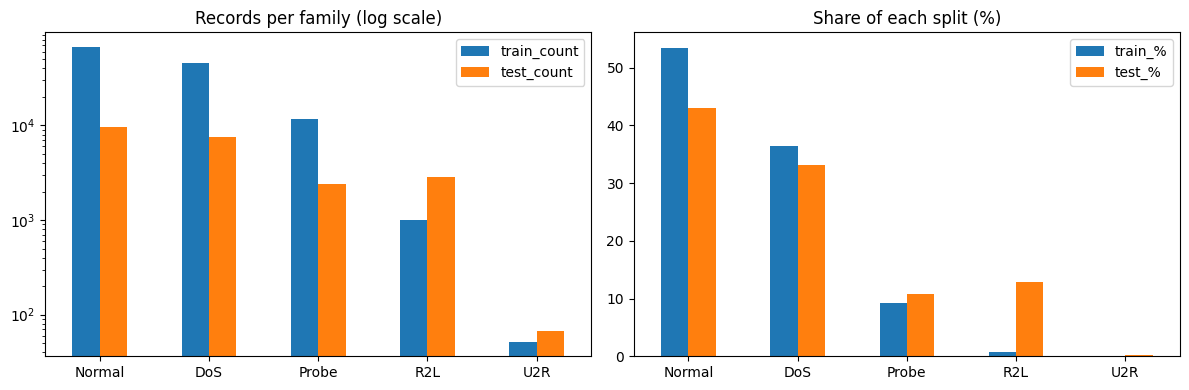

In [4]:
class_distribution = pd.DataFrame({
    "train_count": pd.Series(ytr).value_counts().reindex(CLASSES),
    "test_count": pd.Series(yte).value_counts().reindex(CLASSES)
})
class_distribution["train_%"] = 100 * class_distribution["train_count"] / len(ytr)
class_distribution["test_%"] = 100 * class_distribution["test_count"] / len(yte)
print(class_distribution.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_distribution[["train_count", "test_count"]].plot(kind="bar", logy=True, rot=0, ax=axes[0])
axes[0].set_title("Records per family (log scale)")
class_distribution[["train_%", "test_%"]].plot(kind="bar", rot=0, ax=axes[1])
axes[1].set_title("Share of each split (%)")
plt.tight_layout()
plt.show()

R2L goes from under 1% of training to about 13% of test, and most of that test R2L is made of techniques that are rare or missing in training.

In [5]:
attack_table = pd.DataFrame({
    "family": pd.concat([train_df, test_df]).groupby("label")["family"].first(),
    "train_rows": train_df["label"].value_counts(),
    "test_rows": test_df["label"].value_counts()
}).fillna(0)
attack_table[["train_rows", "test_rows"]] = attack_table[["train_rows", "test_rows"]].astype(int)
attack_table["test_only"] = attack_table["train_rows"] == 0

print("R2L and U2R techniques in each split:")
display(attack_table[attack_table["family"].isin(["R2L", "U2R"])]
        .sort_values(["family", "test_rows"], ascending=[True, False]))

R2L and U2R techniques in each split:


,family,train_rows,test_rows,test_only
label,,,,
guess_passwd,R2L,53,1231,False
warezmaster,R2L,20,944,False
snmpguess,R2L,0,331,True
snmpgetattack,R2L,0,178,True
httptunnel,R2L,0,133,True
multihop,R2L,7,18,False
named,R2L,0,17,True
sendmail,R2L,0,14,True
xlock,R2L,0,9,True


*Source: Repo `01_eda`.* Distribution of every attack label in training.

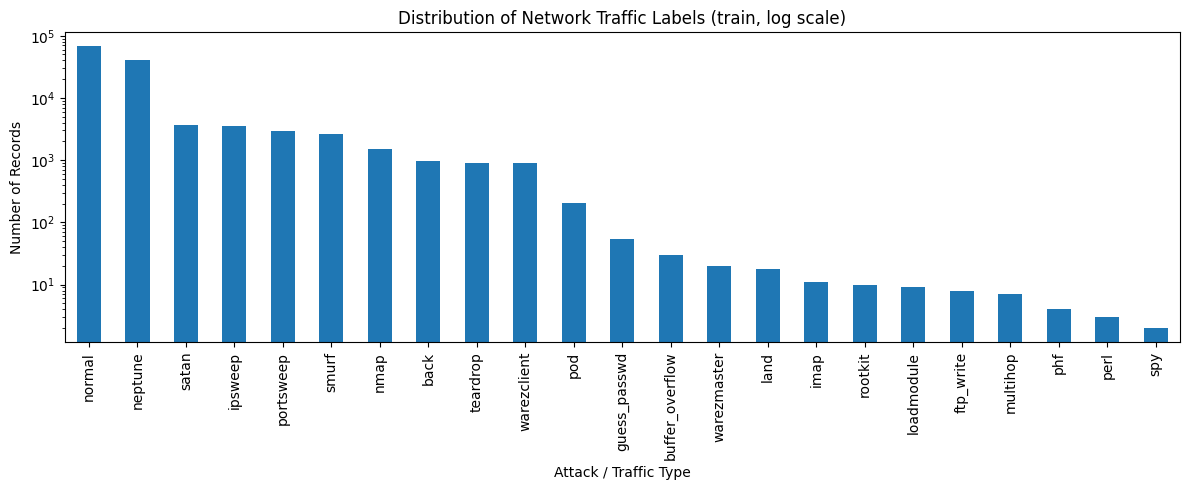

In [6]:
label_counts = train_df["label"].value_counts()
plt.figure(figsize=(12, 5))
label_counts.plot(kind="bar", logy=True)
plt.title("Distribution of Network Traffic Labels (train, log scale)")
plt.xlabel("Attack / Traffic Type")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [7]:
categorical_features = ["protocol_type", "service", "flag"]

for feature in categorical_features:
    print(f"{feature}: {train_df[feature].nunique()} unique values in train")

print("\nProtocol type within each family (% of train rows):")
print((pd.crosstab(train_df["family"], train_df["protocol_type"], normalize="index") * 100).round(2))

print("\nFlag within each family (% of train rows):")
print((pd.crosstab(train_df["family"], train_df["flag"], normalize="index") * 100).round(1))

protocol_type: 3 unique values in train
service: 70 unique values in train
flag: 11 unique values in train

Protocol type within each family (% of train rows):
protocol_type   icmp     tcp    udp
family                             
DoS             6.20   91.86   1.94
Normal          1.94   79.59  18.46
Probe          35.48   50.25  14.28
R2L             0.00  100.00   0.00
U2R             0.00   94.23   5.77

Flag within each family (% of train rows):
flag    OTH   REJ  RSTO  RSTOS0  RSTR    S0   S1   S2   S3    SF   SH
family                                                               
DoS     0.0  12.3   2.6     0.0   0.2  74.8  0.0  0.0  0.0  10.0  0.0
Normal  0.0   4.0   0.3     0.0   0.2   0.5  0.5  0.2  0.1  94.1  0.0
Probe   0.3  24.6   0.7     0.9  18.7   1.3  0.0  0.0  0.0  51.2  2.3
R2L     0.0   0.0   4.6     0.0   0.5   0.0  0.1  0.1  0.3  94.0  0.4
U2R     0.0   0.0   1.9     0.0   0.0   0.0  0.0  0.0  0.0  98.1  0.0


Numeric checks from the repo: constant columns are dropped, heavily skewed byte/count columns get a log transform.

In [8]:
numerical_features = [c for c in column_names if c not in categorical_features + ["label", "difficulty"]]

constant_features = [c for c in numerical_features if train_df[c].nunique() == 1]
print("Constant features:", constant_features)

skewness = train_df[numerical_features].skew().sort_values(ascending=False)
print("\nMost skewed features:")
print(skewness.head(8).round(1))

zero_share = (train_df[numerical_features] == 0).mean().sort_values(ascending=False) * 100
print("\nFeatures that are zero in more than 90% of rows:", (zero_share > 90).sum())

selected_features = ["src_bytes", "dst_bytes", "duration", "logged_in", "count", "same_srv_rate"]
print("\nMean of a few features per family:")
print(train_df.groupby("family")[selected_features].mean().round(2))

Constant features: ['num_outbound_cmds']

Most skewed features:
is_host_login      354.9
dst_bytes          290.1
num_compromised    250.1
num_root           236.9
src_bytes          190.7
urgent             149.9
land                71.0
num_shells          59.6
dtype: float64

Features that are zero in more than 90% of rows: 16

Mean of a few features per family:
        src_bytes  dst_bytes  duration  logged_in   count  same_srv_rate
family                                                                  
DoS       1176.32     169.20      0.01       0.02  178.09           0.19
Normal   13133.28    4329.69    168.59       0.71   22.52           0.97
Probe   385679.84  181074.91   2074.86       0.01   77.05           0.70
R2L     307727.30   81822.03    633.42       0.91    1.30           1.00
U2R        906.23    5141.96     80.94       0.88    5.81           0.93


*Source: Repo `01_eda`.* Per-family averages: R2L/U2R are logged-in sessions with few connections (they look like Normal), DoS has a huge `count`.

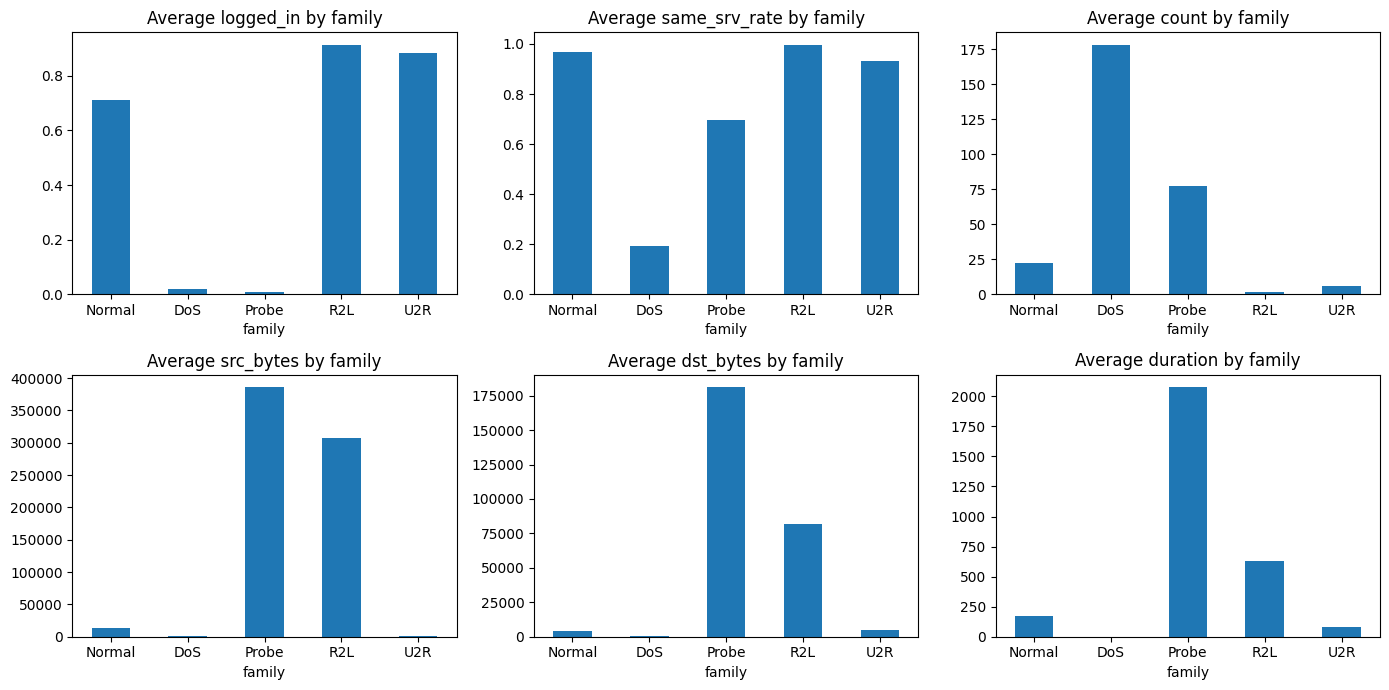

In [9]:
category_means = train_df.groupby("family")[numerical_features].mean().reindex(CLASSES)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feature in zip(axes.ravel(), ["logged_in", "same_srv_rate", "count", "src_bytes", "dst_bytes", "duration"]):
    category_means[feature].plot(kind="bar", ax=ax, rot=0)
    ax.set_title(f"Average {feature} by family")
plt.tight_layout()
plt.show()

In [10]:
corr = train_df[[c for c in numerical_features if c not in constant_features]].corr()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
top_corr = upper.stack().sort_values(key=abs, ascending=False).head(10)
print("Top 10 feature correlations:")
print(top_corr.round(3))

Top 10 feature correlations:
num_compromised       num_root                    0.999
serror_rate           srv_serror_rate             0.993
rerror_rate           srv_rerror_rate             0.989
srv_serror_rate       dst_host_srv_serror_rate    0.986
dst_host_serror_rate  dst_host_srv_serror_rate    0.985
serror_rate           dst_host_srv_serror_rate    0.981
                      dst_host_serror_rate        0.979
srv_serror_rate       dst_host_serror_rate        0.978
srv_rerror_rate       dst_host_srv_rerror_rate    0.970
rerror_rate           dst_host_srv_rerror_rate    0.964
dtype: float64


**What EDA tells us**
- Strong imbalance (U2R = 52 rows, R2L = 995 rows), so we judge models on macro F1 and per-class results too, and we use class weighting.
- DoS sits in `S0`/`REJ` flags and Probe in ICMP/`REJ`/`RSTR`. R2L and U2R look like normal `SF` TCP sessions, which makes them the hardest families.

## Task 5 — Train vs Test Drift
*Source: Repo `04` (KS test) + IDS_Final (KS on Normal traffic only).* A KS statistic near 0 means the train and test distributions match. Drift in *Normal* traffic is what later pushes test false alarms up.

                     feature  KS_all_rows  KS_normal_only
29    dst_host_same_srv_rate        0.105           0.159
30    dst_host_diff_srv_rate        0.104           0.159
28        dst_host_srv_count        0.111           0.152
19                 srv_count        0.062           0.138
18                     count        0.084           0.110
2                  dst_bytes        0.124           0.107
1                  src_bytes        0.082           0.091
0                   duration        0.077           0.075
36  dst_host_srv_rerror_rate        0.168           0.061
27            dst_host_count        0.061           0.055


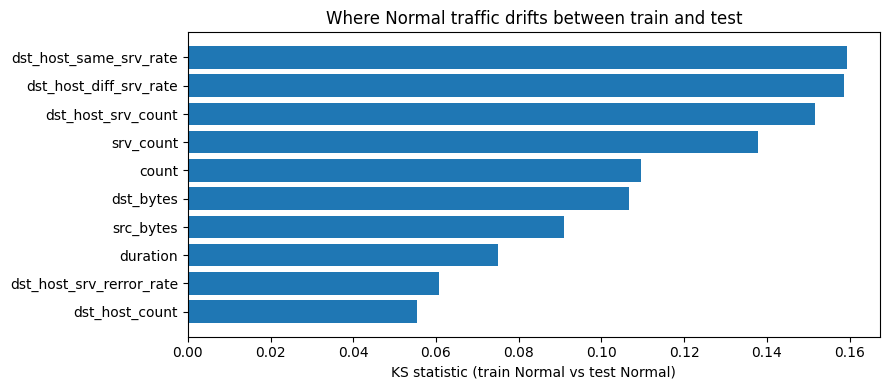

In [11]:
numeric_used = [c for c in numerical_features if c not in constant_features]

ks_rows = []
for feature in numeric_used:
    ks_all = ks_2samp(train_df[feature], test_df[feature]).statistic
    ks_normal = ks_2samp(train_df.loc[train_df["family"] == "Normal", feature],
                         test_df.loc[test_df["family"] == "Normal", feature]).statistic
    ks_rows.append({"feature": feature, "KS_all_rows": ks_all, "KS_normal_only": ks_normal})

ks_df = pd.DataFrame(ks_rows).sort_values("KS_normal_only", ascending=False)
print(ks_df.head(10).round(3))

plt.figure(figsize=(9, 4))
top = ks_df.head(10)
plt.barh(top["feature"][::-1], top["KS_normal_only"][::-1])
plt.xlabel("KS statistic (train Normal vs test Normal)")
plt.title("Where Normal traffic drifts between train and test")
plt.tight_layout()
plt.show()

## Task 6 — Preprocessing and Feature Engineering
*Source: IDS_Final (log features + byte ratio, one-hot with the training vocabulary) using the repo's `OneHotEncoder(handle_unknown="ignore")`.* Tree models don't need scaling, so scaling is only used inside the linear models. An unseen test category becomes an all-zero row.

In [12]:
def engineer(df):
    out = df.copy()
    src = out["src_bytes"].astype(np.float64)
    dst = out["dst_bytes"].astype(np.float64)
    out["log_src_bytes"] = np.log1p(src)
    out["log_dst_bytes"] = np.log1p(dst)
    out["log_count"] = np.log1p(out["count"].astype(np.float64))
    out["log_srv_count"] = np.log1p(out["srv_count"].astype(np.float64))
    out["log_duration"] = np.log1p(out["duration"].astype(np.float64))
    out["byte_ratio"] = src / (src + dst + 1.0)
    return out


train = engineer(train_df)
test = engineer(test_df)

engineered = ["log_src_bytes", "log_dst_bytes", "log_count", "log_srv_count", "log_duration", "byte_ratio"]
numeric_cols = [c for c in numerical_features + engineered if train[c].nunique() > 1]

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(train[categorical_features].astype(str))
cat_levels = {c: list(levels) for c, levels in zip(categorical_features, encoder.categories_)}


def build_matrix(frame):
    numeric_part = frame[numeric_cols].to_numpy(dtype=np.float32)
    categorical_part = encoder.transform(frame[categorical_features].astype(str))
    return np.hstack([numeric_part, categorical_part]).astype(np.float32)


Xtr = build_matrix(train)
Xte = build_matrix(test)
feature_names = numeric_cols + list(encoder.get_feature_names_out())

print("Train matrix:", Xtr.shape, "| Test matrix:", Xte.shape)
print("Unseen test categories:", {c: sorted(set(test[c].astype(str)) - set(cat_levels[c])) for c in categorical_features})

Train matrix: (125973, 127) | Test matrix: (22544, 127)
Unseen test categories: {'protocol_type': [], 'service': [], 'flag': []}


*Source: Repo (`01_eda` Tasks 1–10).* The repo's own pipeline is kept as well, so its models can be rebuilt and compared fairly: drop the constant column, log + scale `src_bytes`, `dst_bytes` and `duration`, scale the rest, and one-hot the 3 categorical columns. It is fitted on the repo's random 80% split only.

In [13]:
repo_features = [c for c in column_names[:41] if c != "num_outbound_cmds"]
repo_log = ["src_bytes", "dst_bytes", "duration"]
repo_numeric = [c for c in repo_features if c not in categorical_features + repo_log]

repo_preprocessor = ColumnTransformer([
    ("log_numeric", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                              ("scaler", StandardScaler())]), repo_log),
    ("numeric", StandardScaler(), repo_numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
])

r_fit, r_val = train_test_split(np.arange(len(train_df)), test_size=0.20, random_state=SEED, stratify=ytr)
R_train = repo_preprocessor.fit_transform(train_df.iloc[r_fit][repo_features])
R_val = repo_preprocessor.transform(train_df.iloc[r_val][repo_features])
R_test = repo_preprocessor.transform(test_df[repo_features])
repo_feature_names = repo_preprocessor.get_feature_names_out()
y_r_train, y_r_val = ytr[r_fit], ytr[r_val]

print("Repo processed train / val / test:", R_train.shape, R_val.shape, R_test.shape)

Repo processed train / val / test: (100778, 121) (25195, 121) (22544, 121)


*Source: Repo (PCA, `01_eda` Task 12).* We keep the components that explain 95% of the variance. PCA is a check only: in the repo's own test, Random Forest on PCA components scored a lower macro F1 (0.898) than on the full features (0.963). So the final models use the full features.

Components for 90% variance: 19
Components for 95% variance: 23


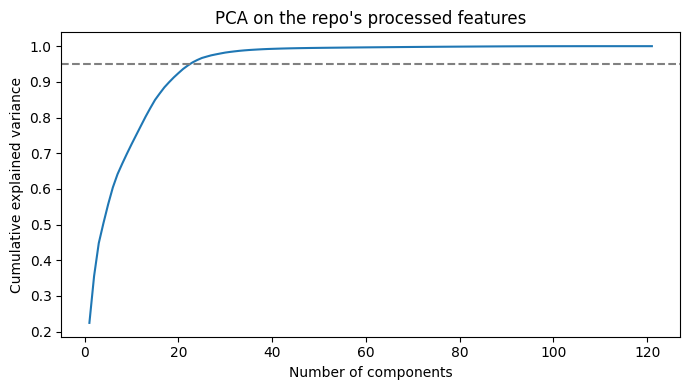

In [14]:
pca_full = PCA().fit(R_train)
cumulative = pca_full.explained_variance_ratio_.cumsum()
print("Components for 90% variance:", int(np.argmax(cumulative >= 0.90)) + 1)
print("Components for 95% variance:", int(np.argmax(cumulative >= 0.95)) + 1)


plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(cumulative) + 1), cumulative)
plt.axhline(0.95, ls="--", color="grey")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA on the repo's processed features")
plt.tight_layout()
plt.show()

## Task 7 — Validation Design
*Source: IDS_Final (leave-attack-type-out), chosen over the repo's random 80/20 split.* A random split keeps the same attack techniques in train and validation, so the repo's validation scores reached about 99.9% and then fell to about 80% on test. Here each family's attack *names* are spread over 3 folds, so every validation fold only has techniques its training part has never seen, which is what the test set looks like.

In [15]:
def leave_attack_type_out_folds(frame, n_folds, seed):
    rng = np.random.default_rng(seed)
    fold = np.empty(len(frame), dtype=np.int64)
    is_normal = (frame["family"] == "Normal").to_numpy()
    fold[is_normal] = rng.integers(0, n_folds, is_normal.sum())
    assignment = {}
    for fam in ATTACK_FAMILIES:
        names = sorted(frame.loc[frame["family"] == fam, "label"].unique())
        names = list(rng.permutation(names))
        for i, name in enumerate(names):
            assignment[name] = i % n_folds
    fold[~is_normal] = frame["label"][~is_normal].map(assignment).to_numpy()
    return fold, assignment


fold_id, fold_assignment = leave_attack_type_out_folds(train, FOLDS, SEED)

for f in range(FOLDS):
    assert set(ytr[fold_id != f]) == set(CLASSES)   # every training part still has every family
    held = {fam: sorted(str(n) for n, k in fold_assignment.items() if k == f and attack_category_map[n] == fam)
            for fam in ATTACK_FAMILIES}
    print(f"Fold {f}: held-out techniques -> {held}")

Fold 0: held-out techniques -> {'DoS': ['smurf', 'teardrop'], 'Probe': ['ipsweep', 'nmap'], 'R2L': ['guess_passwd', 'imap', 'multihop'], 'U2R': ['buffer_overflow', 'rootkit']}
Fold 1: held-out techniques -> {'DoS': ['land', 'neptune'], 'Probe': ['portsweep'], 'R2L': ['ftp_write', 'phf', 'spy'], 'U2R': ['perl']}
Fold 2: held-out techniques -> {'DoS': ['back', 'pod'], 'Probe': ['satan'], 'R2L': ['warezclient', 'warezmaster'], 'U2R': ['loadmodule']}


## Task 8 — Class Imbalance
*Source: Repo (balanced class weights) + IDS_Final (also tests random oversampling).* Both ideas go into the model comparison below, and validation decides which one wins.

In [16]:
weights = compute_class_weight(class_weight="balanced", classes=np.array(CLASSES), y=ytr)
for class_name, weight in zip(CLASSES, weights):
    print(f"{class_name}: {weight:.3f}")

Normal: 0.374
DoS: 0.549
Probe: 2.162
R2L: 25.321
U2R: 484.512


## Task 9 — Supervised and Ensemble Models on Leave-Attack-Type-Out Validation
*Source: both.* The candidates are the repo's models (LR, DT, RF, tuned RF `depth 20`, XGBoost) and IDS_Final's (Extra Trees, gradient boosting unweighted / class-weighted / oversampled, soft vote). We add XGBoost with balanced weights. The linear models use SGD so they can handle 126k rows.

**Selection rule (set before testing):** highest validation **accuracy** among models with validation Normal false alarms ≤ 3%, so precision stays high. Ties go to higher attack precision.

In [17]:
HGB_PARAMETERS = dict(learning_rate=0.06, max_iter=280, max_depth=10, min_samples_leaf=12, random_state=SEED)
XGB_PARAMETERS = dict(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                      objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
                      random_state=SEED, n_jobs=CPU_THREADS)


def new_model(name):
    if name == "Logistic regression":
        return make_pipeline(StandardScaler(), SGDClassifier(loss="log_loss", alpha=1e-4, class_weight="balanced",
                             early_stopping=True, n_iter_no_change=10, max_iter=1000, tol=1e-3, random_state=SEED))
    if name == "Linear SVM":
        return make_pipeline(StandardScaler(), SGDClassifier(loss="modified_huber", alpha=1e-4, class_weight="balanced",
                             early_stopping=True, n_iter_no_change=10, max_iter=1000, tol=1e-3, random_state=SEED))
    if name == "Decision tree":
        return DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, class_weight="balanced", random_state=SEED)
    if name == "Random forest":
        return RandomForestClassifier(n_estimators=150, min_samples_leaf=2, max_features="sqrt",
                                      class_weight="balanced_subsample", n_jobs=CPU_THREADS, random_state=SEED)
    if name == "Random forest (repo tuned, depth 20)":
        return RandomForestClassifier(n_estimators=300, max_depth=20, class_weight="balanced",
                                      n_jobs=CPU_THREADS, random_state=SEED)
    if name == "Extra trees":
        return ExtraTreesClassifier(n_estimators=150, max_depth=32, min_samples_leaf=2,
                                    class_weight="balanced", n_jobs=CPU_THREADS, random_state=SEED)
    if name in ["XGBoost (repo)", "XGBoost (balanced weights)"]:
        return XGBClassifier(**XGB_PARAMETERS)
    if name == "Gradient boosting (class-weighted)":
        return HistGradientBoostingClassifier(class_weight="balanced", **HGB_PARAMETERS)
    if name in ["Gradient boosting (unweighted)", "Gradient boosting (oversampled)"]:
        return HistGradientBoostingClassifier(**HGB_PARAMETERS)
    raise KeyError(name)


def oversample_rows(labels, seed):
    # repeat real R2L / U2R rows (no synthetic values)
    rng = np.random.default_rng(seed)
    parts = [np.arange(len(labels))]
    for label, target in [("R2L", 8000), ("U2R", 2000)]:
        pool = np.flatnonzero(labels == label)
        parts.append(rng.choice(pool, size=max(0, target - len(pool)), replace=True))
    return rng.permutation(np.concatenate(parts))


def fit_model(name, X, y):
    model = new_model(name)
    if name == "Gradient boosting (oversampled)":
        rows = oversample_rows(y, SEED)
        return model.fit(X[rows], y[rows])
    if name.startswith("XGBoost"):
        codes = pd.Series(y).map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
        weights = compute_sample_weight("balanced", codes) if "balanced" in name else None
        return model.fit(X, codes, sample_weight=weights)
    return model.fit(X, y)


def predict_scores(model, X):
    # probabilities with columns in CLASSES order
    proba = model.predict_proba(X)
    if isinstance(model, XGBClassifier):
        return proba
    order = [list(model.classes_).index(c) for c in CLASSES]
    return proba[:, order]


def to_family(scores):
    return np.asarray(CLASSES)[np.asarray(scores).argmax(axis=1)]


def soft_vote(scores):
    return 0.5 * scores["Gradient boosting (class-weighted)"] + 0.5 * scores["Random forest"]


MODEL_NAMES = ["Logistic regression", "Linear SVM", "Decision tree", "Random forest",
               "Random forest (repo tuned, depth 20)", "Extra trees", "XGBoost (repo)",
               "XGBoost (balanced weights)", "Gradient boosting (unweighted)",
               "Gradient boosting (class-weighted)", "Gradient boosting (oversampled)"]
ENSEMBLE = "Soft vote (boosting + random forest)"

Each model is trained on two folds and scored on the third, so every training row gets an out-of-fold score.

In [18]:
oof_scores = {name: np.zeros((len(train), len(CLASSES))) for name in MODEL_NAMES}

for f in range(FOLDS):
    fit_rows, val_rows = fold_id != f, fold_id == f
    for name in MODEL_NAMES:
        start = time.perf_counter()
        model = fit_model(name, Xtr[fit_rows], ytr[fit_rows])
        oof_scores[name][val_rows] = predict_scores(model, Xtr[val_rows])
        print(f"fold {f + 1}/{FOLDS}  {name:40s} {time.perf_counter() - start:6.1f}s", flush=True)

oof_scores[ENSEMBLE] = soft_vote(oof_scores)

fold 1/3  Logistic regression                         1.7s


fold 1/3  Linear SVM                                  1.3s


fold 1/3  Decision tree                               0.8s


fold 1/3  Random forest                               5.5s


fold 1/3  Random forest (repo tuned, depth 20)        8.9s


fold 1/3  Extra trees                                 6.2s


... (23 outputs left out)

fold 3/3  XGBoost (balanced weights)                 11.3s


fold 3/3  Gradient boosting (unweighted)              2.9s


fold 3/3  Gradient boosting (class-weighted)          4.3s


fold 3/3  Gradient boosting (oversampled)            11.6s


In [19]:
def normal_fpr(truth, predicted):
    return float(np.mean(predicted[truth == "Normal"] != "Normal"))


def summary_row(name, truth, predicted, attack_score=None):
    truth = np.asarray(truth)
    predicted = np.asarray(predicted)
    _, recall, _, _ = precision_recall_fscore_support(truth, predicted, labels=CLASSES, zero_division=0)
    is_attack, says_attack = truth != "Normal", predicted != "Normal"
    row = {
        "model": name,
        "accuracy": accuracy_score(truth, predicted),
        "macro_f1": f1_score(truth, predicted, labels=CLASSES, average="macro", zero_division=0),
        "weighted_f1": f1_score(truth, predicted, labels=CLASSES, average="weighted", zero_division=0),
        "macro_precision": precision_score(truth, predicted, labels=CLASSES, average="macro", zero_division=0),
        "attack_precision": precision_score(is_attack, says_attack, zero_division=0),
        "attack_detection": float(np.mean(says_attack[is_attack])),
        "normal_fpr": normal_fpr(truth, predicted),
        "R2L_recall": recall[3],
        "U2R_recall": recall[4],
    }
    if attack_score is not None:
        row["roc_auc"] = roc_auc_score(is_attack, attack_score)
        row["pr_auc"] = average_precision_score(is_attack, attack_score)
    return row


validation_table = pd.DataFrame([summary_row(name, ytr, to_family(s), 1 - s[:, 0])
                                 for name, s in oof_scores.items()])
eligible = validation_table[validation_table["normal_fpr"] <= 0.03]
SELECTED_NAME = eligible.sort_values(["accuracy", "attack_precision"], ascending=False).iloc[0]["model"]

print("Leave-attack-type-out validation (attack rows are always unseen techniques):")
display(validation_table.sort_values("accuracy", ascending=False).round(4))
print("FROZEN SELECTION:", SELECTED_NAME)

Leave-attack-type-out validation (attack rows are always unseen techniques):


,model,accuracy,macro_f1,weighted_f1,macro_precision,attack_precision,attack_detection,normal_fpr,R2L_recall,U2R_recall,roc_auc,pr_auc
9,Gradient boosting (class-weighted),0.6099,0.2945,0.5354,0.3290,0.9969,0.8609,0.0023,0.0080,0.1923,0.9914,0.9911
11,Soft vote (boosting + random forest),0.6039,0.3012,0.5299,0.3990,0.9983,0.8434,0.0013,0.0080,0.1731,0.9968,0.9959
7,XGBoost (balanced weights),0.6005,0.3654,0.5182,0.4894,0.9992,0.7813,0.0006,0.0211,0.5000,0.9916,0.9917
2,Decision tree,0.5876,0.2895,0.5225,0.3457,0.9922,0.7833,0.0054,0.0291,0.2500,0.8934,0.8848
10,Gradient boosting (oversampled),0.5864,0.2905,0.5173,0.6183,0.9991,0.7546,0.0006,0.0141,0.1731,0.9920,0.9915
8,Gradient boosting (unweighted),0.5829,0.2490,0.5226,0.3431,0.9941,0.7933,0.0041,0.0442,0.0769,0.9540,0.9487
6,XGBoost (repo),0.5816,0.3101,0.4805,0.4824,0.9991,0.5878,0.0004,0.0141,0.2885,0.9905,0.9907
5,Extra trees,0.5747,0.3049,0.4647,0.3368,0.9923,0.4998,0.0034,0.0261,0.5000,0.9891,0.9847
3,Random forest,0.5742,0.2802,0.4975,0.4509,0.9991,0.7258,0.0006,0.0121,0.1923,0.9962,0.9952
1,Linear SVM,0.5692,0.2284,0.4578,0.3724,0.9673,0.3766,0.0111,0.0020,0.0962,0.7427,0.7245


FROZEN SELECTION: Gradient boosting (class-weighted)


## Task 10 — Feature Engineering Check: Repo's OOF Target Encoding of `service`
*Source: Repo (`03`, OOF target encoding).* We add the 5 per-class service encodings to the selected model and keep them only if validation accuracy goes up. The encodings are computed out-of-fold inside each training part, so there is no leak.

In [20]:
def service_encoding(fit_service, fit_y, apply_service, smoothing=10):
    counts = pd.crosstab(fit_service, fit_y).reindex(columns=CLASSES, fill_value=0)
    prior = pd.Series(fit_y).value_counts(normalize=True).reindex(CLASSES, fill_value=0)
    encoded = (counts + smoothing * prior) / (counts.sum(axis=1).to_numpy()[:, None] + smoothing)
    out = encoded.reindex(apply_service.to_numpy())
    return out.fillna(prior).to_numpy(dtype=np.float32)


def oof_service_encoding(service, y, n_splits=5):
    out = np.zeros((len(service), len(CLASSES)), dtype=np.float32)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    for fit_idx, hold_idx in skf.split(np.zeros(len(y)), y):
        out[hold_idx] = service_encoding(service.iloc[fit_idx], y[fit_idx], service.iloc[hold_idx])
    return out


te_oof = np.zeros((len(train), len(CLASSES)))
for f in range(FOLDS):
    fit_rows, val_rows = np.flatnonzero(fold_id != f), np.flatnonzero(fold_id == f)
    service_fit = train["service"].iloc[fit_rows]
    X_fit = np.hstack([Xtr[fit_rows], oof_service_encoding(service_fit, ytr[fit_rows])])
    X_val = np.hstack([Xtr[val_rows], service_encoding(service_fit, ytr[fit_rows], train["service"].iloc[val_rows])])
    model = fit_model(SELECTED_NAME, X_fit, ytr[fit_rows])
    te_oof[val_rows] = predict_scores(model, X_val)

te_check = pd.DataFrame([summary_row(SELECTED_NAME, ytr, to_family(oof_scores[SELECTED_NAME])),
                         summary_row(SELECTED_NAME + " + service target encoding", ytr, to_family(te_oof))])
display(te_check[["model", "accuracy", "macro_f1", "attack_precision", "normal_fpr"]].round(4))

USE_TARGET_ENCODING = te_check.iloc[1]["accuracy"] > te_check.iloc[0]["accuracy"]
print("Keep service target encoding:", USE_TARGET_ENCODING)

if USE_TARGET_ENCODING:
    Xtr_model = np.hstack([Xtr, oof_service_encoding(train["service"], ytr)])
    Xte_model = np.hstack([Xte, service_encoding(train["service"], ytr, test["service"])])
    oof_scores[SELECTED_NAME] = te_oof
else:
    Xtr_model, Xte_model = Xtr, Xte

,model,accuracy,macro_f1,attack_precision,normal_fpr
0,Gradient boosting (class-weighted),0.6099,0.2945,0.9969,0.0023
1,Gradient boosting (class-weighted) + service t...,0.5694,0.2429,0.9968,0.0020


Keep service target encoding: False


## Task 11 — Why the Repo's Random Split Was Misleading
*Source: Repo split vs IDS_Final split.* The same models get a much higher macro F1 on a random split than on unseen techniques. The random split is the "too good to be true" number.

In [21]:
rand_fit, rand_val = train_test_split(np.arange(len(train)), test_size=0.2, stratify=ytr, random_state=SEED)
random_rows = []
for name in sorted({SELECTED_NAME, "XGBoost (repo)", "Gradient boosting (oversampled)"}):
    model = fit_model(name, Xtr[rand_fit], ytr[rand_fit])
    predicted = to_family(predict_scores(model, Xtr[rand_val]))
    random_rows.append({"model": name,
                        "random_split_macro_f1": f1_score(ytr[rand_val], predicted, average="macro"),
                        "leave_attack_out_macro_f1": validation_table.set_index("model").loc[name, "macro_f1"]})
display(pd.DataFrame(random_rows).round(4))

,model,random_split_macro_f1,leave_attack_out_macro_f1
0,Gradient boosting (class-weighted),0.8941,0.2945
1,Gradient boosting (oversampled),0.9779,0.2905
2,XGBoost (repo),0.9615,0.3101


## Task 12 — Official Test Evaluation of Every Candidate
*Source: IDS_Final (refit on all of `KDDTrain+`, score `KDDTest+` once).* The primary model is the one frozen in Task 9, whatever this table shows.

In [22]:
final_models, test_scores = {}, {}
for name in MODEL_NAMES:
    start = time.perf_counter()
    final_models[name] = fit_model(name, Xtr, ytr)
    test_scores[name] = predict_scores(final_models[name], Xte)
    print(f"refitted {name:40s} {time.perf_counter() - start:6.1f}s", flush=True)
test_scores[ENSEMBLE] = soft_vote(test_scores)

if USE_TARGET_ENCODING:
    final_models[SELECTED_NAME] = fit_model(SELECTED_NAME, Xtr_model, ytr)
    test_scores[SELECTED_NAME] = predict_scores(final_models[SELECTED_NAME], Xte_model)

primary_scores = test_scores[SELECTED_NAME]
primary_prediction = to_family(primary_scores)

comparison = pd.DataFrame([summary_row(name, yte, to_family(s), 1 - s[:, 0]) for name, s in test_scores.items()])
comparison["selected"] = comparison["model"] == SELECTED_NAME
print("KDDTest+ results for all candidates:")
display(comparison.sort_values("accuracy", ascending=False).round(4))

refitted Logistic regression                         2.1s


refitted Linear SVM                                  1.5s


refitted Decision tree                               1.0s


refitted Random forest                               7.4s


refitted Random forest (repo tuned, depth 20)       12.4s


refitted Extra trees                                 8.3s


... (3 outputs left out)

refitted Gradient boosting (class-weighted)          7.1s


refitted Gradient boosting (oversampled)            18.3s


KDDTest+ results for all candidates:


,model,accuracy,macro_f1,weighted_f1,macro_precision,attack_precision,attack_detection,normal_fpr,R2L_recall,U2R_recall,roc_auc,pr_auc,selected
9,Gradient boosting (class-weighted),0.8024,0.6861,0.7857,0.8302,0.9693,0.7061,0.0296,0.2787,0.3881,0.9458,0.9550,True
7,XGBoost (balanced weights),0.7944,0.6337,0.7650,0.8497,0.9708,0.6869,0.0273,0.1470,0.2985,0.9654,0.9653,False
11,Soft vote (boosting + random forest),0.7903,0.6482,0.7659,0.8404,0.9702,0.6813,0.0277,0.1872,0.3134,0.9665,0.9701,False
8,Gradient boosting (unweighted),0.7770,0.5541,0.7488,0.6729,0.9610,0.6838,0.0367,0.1255,0.3731,0.9557,0.9406,False
0,Logistic regression,0.7769,0.5504,0.7487,0.6423,0.9663,0.6961,0.0321,0.0984,0.4776,0.7859,0.8831,False
10,Gradient boosting (oversampled),0.7758,0.5576,0.7399,0.8259,0.9673,0.6471,0.0289,0.0936,0.1194,0.9704,0.9739,False
6,XGBoost (repo),0.7746,0.5574,0.7353,0.8381,0.9685,0.6522,0.0280,0.0704,0.1493,0.9652,0.9675,False
5,Extra trees,0.7716,0.6294,0.7371,0.8089,0.9671,0.6450,0.0290,0.0908,0.4627,0.9689,0.9727,False
1,Linear SVM,0.7664,0.5820,0.7438,0.7339,0.9670,0.6353,0.0286,0.1990,0.1791,0.8274,0.8483,False
3,Random forest,0.7471,0.5229,0.7066,0.8125,0.9656,0.5950,0.0280,0.0492,0.1045,0.9707,0.9733,False


Per-class report and confusion matrix for the primary model (the repo's report style).

PRIMARY MODEL: Gradient boosting (class-weighted)
              precision    recall  f1-score   support

      Normal     0.7142    0.9704    0.8228      9711
         DoS     0.9629    0.7862    0.8656      7460
       Probe     0.8195    0.8141    0.8168      2421
         R2L     0.9877    0.2787    0.4347      2885
         U2R     0.6667    0.3881    0.4906        67

    accuracy                         0.8024     22544
   macro avg     0.8302    0.6475    0.6861     22544
weighted avg     0.8427    0.8024    0.7857     22544



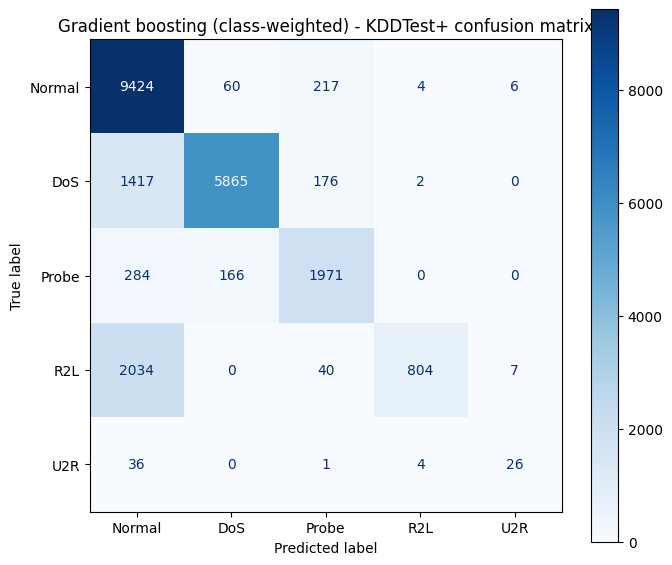

In [23]:
print("PRIMARY MODEL:", SELECTED_NAME)
print(classification_report(yte, primary_prediction, labels=CLASSES, digits=4, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(yte, primary_prediction, labels=CLASSES, cmap="Blues",
                                        values_format="d", ax=ax)
ax.set_title(f"{SELECTED_NAME} - KDDTest+ confusion matrix")
plt.tight_layout()
plt.show()

*Source: IDS_Final.* One-vs-rest ROC and precision–recall curves with AUC. The repo had no ROC/PR curves. PR curves are more honest than ROC for rare classes like U2R.

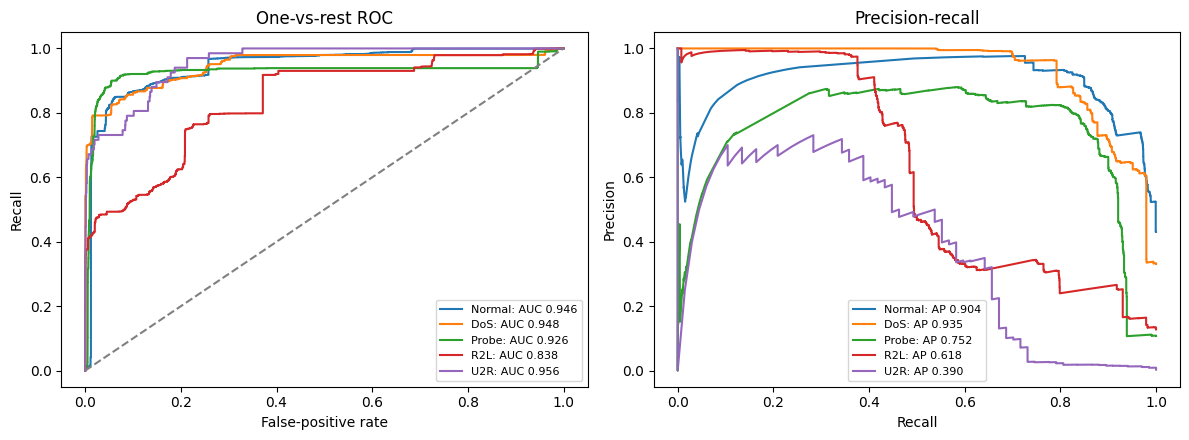

,family,roc_auc,pr_auc,prevalence
0,Normal,0.9458,0.9041,0.4308
1,DoS,0.9478,0.9345,0.3309
2,Probe,0.9259,0.7524,0.1074
3,R2L,0.8381,0.6183,0.1280
4,U2R,0.9562,0.3897,0.0030


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
curve_rows = []
for column, label in enumerate(CLASSES):
    is_label = yte == label
    fpr, tpr, _ = roc_curve(is_label, primary_scores[:, column])
    precision, recall, _ = precision_recall_curve(is_label, primary_scores[:, column])
    auc = roc_auc_score(is_label, primary_scores[:, column])
    ap = average_precision_score(is_label, primary_scores[:, column])
    axes[0].plot(fpr, tpr, label=f"{label}: AUC {auc:.3f}")
    axes[1].plot(recall, precision, label=f"{label}: AP {ap:.3f}")
    curve_rows.append({"family": label, "roc_auc": auc, "pr_auc": ap, "prevalence": is_label.mean()})
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set(xlabel="False-positive rate", ylabel="Recall", title="One-vs-rest ROC")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("../results/ids_nsl_kdd_roc_pr_primary.png", dpi=120)
plt.show()
display(pd.DataFrame(curve_rows).round(4))

In [25]:
breakdown = pd.DataFrame({"attack": test["label"], "family": yte,
                          "correct": primary_prediction == yte, "flagged": primary_prediction != "Normal"})
per_technique = breakdown[breakdown["family"].isin(["R2L", "U2R"])].groupby(["family", "attack"]).agg(
    test_rows=("correct", "size"), family_recall=("correct", "mean"), flagged_as_attack=("flagged", "mean"))
per_technique["train_rows"] = attack_table["train_rows"].reindex(per_technique.index.get_level_values("attack")).to_numpy()
print("R2L / U2R recall per technique (train_rows = examples available to learn from):")
display(per_technique.sort_values("test_rows", ascending=False).round(3))

R2L / U2R recall per technique (train_rows = examples available to learn from):


test_rows  family_recall  flagged_as_attack  train_rows
family attack                                                                  
R2L    guess_passwd          1231          0.051              0.051          53
       warezmaster            944          0.779              0.779          20
       snmpguess              331          0.000              0.003           0
       snmpgetattack          178          0.000              0.000           0
       httptunnel             133          0.000              0.256           0
U2R    buffer_overflow         20          0.450              0.500          30
R2L    multihop                18          0.111              0.389           7
       named                   17          0.059              0.353           0
U2R    ps                      15          0.333              0.467           0
R2L    sendmail                14          0.000              0.071           0
U2R    rootkit                 13          0.308              0.385          10
       xterm                   13          0.385              0.462           0
R2L    xlock                    9          0.000              0.000           0
       xsnoop                   4          0.000              0.250           0
       ftp_write                3          0.333              0.333           8
       phf                      2          0.500              0.500           4
U2R    perl                     2          1.000              1.000           3
       loadmodule               2          0.000              0.000           9
       sqlattack                2          0.500              0.500           0
R2L    imap                     1          1.000              1.000          11

## Task 13 — Repo Baselines Reproduced
*Source: Repo (`03` + `04`).* This is the repo's own pipeline from Task 6 (log + scaling + one-hot, random 80/20 split): a balanced binary Random Forest (300 trees) with the 0.35 threshold the repo picked on its validation split, and a hierarchical Random Forest (depth 20) that names the attack family. We also run the repo's multiclass XGBoost. Retraining them here gives a fair side-by-side comparison on the same test file.

In [26]:
repo_rf_binary = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                        n_jobs=CPU_THREADS, random_state=SEED)
repo_rf_binary.fit(R_train, y_r_train != "Normal")

attack_rows = ytr[r_fit] != "Normal"
repo_hier_rf = RandomForestClassifier(n_estimators=300, max_depth=20, class_weight="balanced",
                                      n_jobs=CPU_THREADS, random_state=SEED)
repo_hier_rf.fit(R_train[attack_rows], ytr[r_fit][attack_rows])


def repo_hierarchical_predict(R):
    attack_proba = repo_rf_binary.predict_proba(R)[:, 1]
    predicted = np.full(len(R), "Normal", dtype=object)
    flagged = attack_proba >= 0.35
    predicted[flagged] = repo_hier_rf.predict(R[flagged])
    return predicted, attack_proba


repo_val_pred, _ = repo_hierarchical_predict(R_val)
print("Repo hierarchical RF on its RANDOM validation split: accuracy",
      round(accuracy_score(ytr[r_val], repo_val_pred), 4))

repo_test_pred, repo_test_attack_proba = repo_hierarchical_predict(R_test)

repo_xgb = fit_model("XGBoost (repo)", R_train, ytr[r_fit])
repo_xgb_scores = predict_scores(repo_xgb, R_test)

repo_rows = [summary_row("Repo: tuned RF + hierarchical RF (0.35)", yte, repo_test_pred, repo_test_attack_proba),
             summary_row("Repo: XGBoost multiclass", yte, to_family(repo_xgb_scores), 1 - repo_xgb_scores[:, 0])]
display(pd.DataFrame(repo_rows).round(4))

Repo hierarchical RF on its RANDOM validation split: accuracy 0.9992


,model,accuracy,macro_f1,weighted_f1,macro_precision,attack_precision,attack_detection,normal_fpr,R2L_recall,U2R_recall,roc_auc,pr_auc
0,Repo: tuned RF + hierarchical RF (0.35),0.7968,0.5959,0.7617,0.8322,0.9688,0.6954,0.0296,0.1036,0.1642,0.9618,0.9654
1,Repo: XGBoost multiclass,0.7802,0.5541,0.7430,0.8168,0.9687,0.6603,0.0282,0.0860,0.1045,0.9686,0.9706


## Task 14 — Second Look for R2L and U2R
*Source: IDS_Final (§12B and the improved §12E-2 version); the repo's hierarchical idea goes in the opposite direction.* The repo's second stage only re-labels rows already flagged as attacks, so R2L rows that the first stage calls Normal are lost. This stage re-checks **only rows the classifier calls Normal**, using behaviour features: logins, failed logins, root shell, file actions, bytes, error rates, a login-service flag, a "small UDP to a private port" flag (SNMP guessing) and the kNN distance to Normal traffic.

- v1 (basic behaviour features) and v2 (extra behaviour + kNN distance) are compared on validation PR AUC, and the better one is kept.
- Threshold: best validation F1 with at most **2% extra false alarms** on validation Normal, so precision is protected.

In [27]:
STAGE2_MAX_EXTRA_FPR = 0.02
STAGE2_CLASSES = ["Normal", "R2L", "U2R"]
TRAFFIC_COLUMNS = [c for c in numerical_features if train[c].nunique() > 1]


def traffic_space(frame):
    return np.log1p(np.clip(frame[TRAFFIC_COLUMNS].to_numpy(dtype=np.float64), 0, None))


# scaled numeric traffic space (fitted on train): used by kNN, clustering and the anomaly detectors
traffic_scaler = StandardScaler().fit(traffic_space(train))
Ztr = traffic_scaler.transform(traffic_space(train)).astype(np.float32)
Zte = traffic_scaler.transform(traffic_space(test)).astype(np.float32)


def fit_knn(normal_space, seed, reference_size=20000):
    rng = np.random.default_rng(seed)
    reference = normal_space[rng.choice(len(normal_space), min(reference_size, len(normal_space)), replace=False)]
    knn = NearestNeighbors(n_neighbors=5, n_jobs=CPU_THREADS).fit(reference)
    return lambda Z: knn.kneighbors(Z)[0].mean(axis=1)


# kNN distance to Normal as a feature; training Normal rows are scored out-of-sample (5 parts)
normal_idx = np.flatnonzero(ytr == "Normal")
full_knn = fit_knn(Ztr[normal_idx], SEED)
knn_tr = full_knn(Ztr)
for part, chunk in enumerate(np.array_split(np.random.default_rng(SEED).permutation(normal_idx), 5)):
    rest = np.setdiff1d(normal_idx, chunk)
    knn_tr[chunk] = fit_knn(Ztr[rest], SEED + 200 + part)(Ztr[chunk])
knn_log_tr, knn_log_te = np.log1p(knn_tr), np.log1p(full_knn(Zte))

In [28]:
BEHAVIOUR_V1 = [c for c in [
    "num_failed_logins", "is_guest_login", "logged_in", "hot", "root_shell", "su_attempted",
    "num_compromised", "num_root", "num_file_creations", "num_shells", "num_access_files",
    "log_src_bytes", "log_dst_bytes", "log_total_bytes", "log_duration", "byte_ratio",
    "log_count", "log_srv_count", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate"]
    if c == "log_total_bytes" or train[c].nunique() > 1]
EXTRA_BEHAVIOUR = [c for c in ["serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
                               "diff_srv_rate", "dst_host_serror_rate", "dst_host_rerror_rate",
                               "dst_host_srv_rerror_rate", "dst_host_diff_srv_rate"] if train[c].nunique() > 1]
BEHAVIOUR_V2 = BEHAVIOUR_V1 + EXTRA_BEHAVIOUR + ["failed_login_rate", "login_service", "udp_private_small", "log_knn_distance"]
LOGIN_SERVICES = ["telnet", "ftp", "pop_3", "imap4", "login", "ssh", "klogin", "kshell", "smtp", "ftp_data"]


def behaviour_matrix(frame, columns, knn_log):
    total = frame["src_bytes"].astype(float) + frame["dst_bytes"].astype(float)
    frame = frame.assign(log_total_bytes=np.log1p(total),
                         failed_login_rate=frame["num_failed_logins"] / (1.0 + frame["count"]),
                         login_service=frame["service"].isin(LOGIN_SERVICES).astype(float),
                         udp_private_small=((frame["protocol_type"] == "udp") & (frame["service"] == "private")
                                            & (total <= 200)).astype(float),
                         log_knn_distance=knn_log)
    numeric_part = frame[columns].to_numpy(dtype=np.float32)
    return np.hstack([numeric_part, encoder.transform(frame[categorical_features].astype(str))]).astype(np.float32)


B1tr, B1te = behaviour_matrix(train, BEHAVIOUR_V1, knn_log_tr), behaviour_matrix(test, BEHAVIOUR_V1, knn_log_te)
B2tr, B2te = behaviour_matrix(train, BEHAVIOUR_V2, knn_log_tr), behaviour_matrix(test, BEHAVIOUR_V2, knn_log_te)


def fit_stage2(X, y):
    keep = np.isin(y, STAGE2_CLASSES)
    model = HistGradientBoostingClassifier(class_weight="balanced", max_iter=150, max_depth=4,
                                           learning_rate=0.08, min_samples_leaf=10, random_state=SEED)
    return model.fit(X[keep], y[keep])


def stage2_outputs(model, X):
    proba = model.predict_proba(X)
    classes = list(model.classes_)
    r2l, u2r = proba[:, classes.index("R2L")], proba[:, classes.index("U2R")]
    return r2l + u2r, u2r / (r2l + u2r)     # attack score, share of it that is U2R

In [29]:
oof_family = to_family(oof_scores[SELECTED_NAME])
reach = oof_family == "Normal"              # rows the classifier calls Normal reach stage 2
target = np.isin(ytr, ["R2L", "U2R"])
n_normal = int((ytr == "Normal").sum())

s2_oof = {"v1": np.zeros(len(train)), "v2": np.zeros(len(train))}
share_oof = np.zeros(len(train))
for f in range(FOLDS):
    fit_rows, val_rows = fold_id != f, fold_id == f
    s2_oof["v1"][val_rows] = stage2_outputs(fit_stage2(B1tr[fit_rows], ytr[fit_rows]), B1tr[val_rows])[0]
    s2_oof["v2"][val_rows], share_oof[val_rows] = stage2_outputs(fit_stage2(B2tr[fit_rows], ytr[fit_rows]), B2tr[val_rows])


def best_stage2_threshold(scores):
    rows = []
    for threshold in np.unique(np.quantile(scores[reach], np.linspace(0.5, 0.9999, 300))):
        fire = reach & (scores >= threshold)
        p, r, f1_, _ = precision_recall_fscore_support(target[reach], fire[reach], average="binary", zero_division=0)
        rows.append({"threshold": float(threshold), "precision": p, "recall": r, "f1": f1_,
                     "extra_normal_fpr": float((fire & (ytr == "Normal")).sum() / n_normal)})
    rows = pd.DataFrame(rows)
    rows = rows[rows["extra_normal_fpr"] <= STAGE2_MAX_EXTRA_FPR]
    return rows.sort_values(["f1", "recall"], ascending=False).iloc[0]


stage2_compare = []
for version in ["v1", "v2"]:
    best = best_stage2_threshold(s2_oof[version])
    stage2_compare.append({"version": version,
                           "val_pr_auc": average_precision_score(target[reach], s2_oof[version][reach]),
                           **best.to_dict()})
stage2_compare = pd.DataFrame(stage2_compare)
display(stage2_compare.round(4))

S2_VERSION = stage2_compare.sort_values("val_pr_auc", ascending=False).iloc[0]["version"]
S2_THRESHOLD = float(stage2_compare.set_index("version").loc[S2_VERSION, "threshold"])
print("FROZEN second stage:", S2_VERSION, "| threshold", round(S2_THRESHOLD, 4))

,version,val_pr_auc,threshold,precision,recall,f1,extra_normal_fpr
0,v1,0.0394,0.5069,0.1940,0.0256,0.0453,0.0015
1,v2,0.3202,0.0369,0.3046,0.4566,0.3654,0.0107


FROZEN second stage: v2 | threshold 0.0369


Class weighting pushes too many rows into the tiny U2R class, so a row is called U2R only if U2R holds a validation-chosen share of its R2L+U2R probability.

In [30]:
fire_val = reach & (s2_oof[S2_VERSION] >= S2_THRESHOLD)
share_rows = []
for cutoff in np.round(np.arange(0.50, 0.96, 0.05), 2):
    predicted = np.where(fire_val, np.where(share_oof >= cutoff, "U2R", "R2L"), "Normal")
    judged = fire_val | target
    share_rows.append({"u2r_share_cutoff": cutoff,
                       "macro_f1_R2L_U2R": f1_score(ytr[judged], predicted[judged], labels=["R2L", "U2R"],
                                                    average="macro", zero_division=0)})
share_table = pd.DataFrame(share_rows)
U2R_SHARE_CUTOFF = float(share_table.sort_values("macro_f1_R2L_U2R", ascending=False).iloc[0]["u2r_share_cutoff"])
print("FROZEN U2R share cutoff:", U2R_SHARE_CUTOFF)

if S2_VERSION == "v1":
    S2_TRAIN, S2_TEST = B1tr, B1te
else:
    S2_TRAIN, S2_TEST = B2tr, B2te

stage2_model = fit_stage2(S2_TRAIN, ytr)
s2_test, share_test = stage2_outputs(stage2_model, S2_TEST)
s2_family = np.where(share_test >= U2R_SHARE_CUTOFF, "U2R", "R2L")
stage2_fire = (primary_prediction == "Normal") & (s2_test >= S2_THRESHOLD)
oof_s2_family = np.where(share_oof >= U2R_SHARE_CUTOFF, "U2R", "R2L")

FROZEN U2R share cutoff: 0.95


## Task 15 — Choosing the Primary System on Validation
*Source: new, combining both.* There are two ways to run the system:
- **Classifier alone** (what the repo and IDS_Final §5 do)
- **Classifier + R2L/U2R second stage** (high-precision mode)

We keep whichever has the higher **validation accuracy** with validation Normal false alarms ≤ 3% (same rule as Task 9). The anomaly layer (Task 17) adds `Unknown attack` labels (counted as wrong) and extra false alarms, so it is an optional **high-recall mode**, not a primary candidate.

In [31]:
oof_with_stage2 = oof_family.astype(object).copy()
oof_with_stage2[fire_val] = oof_s2_family[fire_val]

mode_validation = pd.DataFrame([
    summary_row("Classifier alone", ytr, oof_family),
    summary_row("Classifier + R2L/U2R second stage", ytr, oof_with_stage2)])
display(mode_validation.round(4))

eligible_modes = mode_validation[mode_validation["normal_fpr"] <= 0.03]
PRIMARY_MODE = eligible_modes.sort_values(["accuracy", "attack_precision"], ascending=False).iloc[0]["model"]
print("FROZEN PRIMARY MODE:", PRIMARY_MODE)

with_stage2_prediction = primary_prediction.astype(object).copy()
with_stage2_prediction[stage2_fire] = s2_family[stage2_fire]
with_stage2_score = np.where(stage2_fire, 1 + s2_test, 1 - primary_scores[:, 0])   # ranking score for ROC / PR

if PRIMARY_MODE == "Classifier alone":
    best_prediction = primary_prediction.astype(object)
    best_score = 1 - primary_scores[:, 0]
else:
    best_prediction = with_stage2_prediction
    best_score = with_stage2_score

print(classification_report(yte, best_prediction, labels=CLASSES, digits=4, zero_division=0))
display(pd.DataFrame([summary_row("Primary system on KDDTest+", yte, best_prediction, best_score)]).round(4))

,model,accuracy,macro_f1,weighted_f1,macro_precision,attack_precision,attack_detection,normal_fpr,R2L_recall,U2R_recall
0,Classifier alone,0.6099,0.2945,0.5354,0.3290,0.9969,0.8609,0.0023,0.0080,0.1923
1,Classifier + R2L/U2R second stage,0.6077,0.3693,0.5381,0.3591,0.9832,0.8746,0.0130,0.4462,0.5192


FROZEN PRIMARY MODE: Classifier alone
              precision    recall  f1-score   support

      Normal     0.7142    0.9704    0.8228      9711
         DoS     0.9629    0.7862    0.8656      7460
       Probe     0.8195    0.8141    0.8168      2421
         R2L     0.9877    0.2787    0.4347      2885
         U2R     0.6667    0.3881    0.4906        67

    accuracy                         0.8024     22544
   macro avg     0.8302    0.6475    0.6861     22544
weighted avg     0.8427    0.8024    0.7857     22544



,model,accuracy,macro_f1,weighted_f1,macro_precision,attack_precision,attack_detection,normal_fpr,R2L_recall,U2R_recall,roc_auc,pr_auc
0,Primary system on KDDTest+,0.8024,0.6861,0.7857,0.8302,0.9693,0.7061,0.0296,0.2787,0.3881,0.9458,0.955


## Task 16 — Clustering for Unknown Patterns
*Source: IDS_Final (k chosen by silhouette over k = 4…20, quality measured on the **test** set) + Repo (cluster purity table, distance-based outliers).* The repo measured clusters on training data only and never tested its distance outliers. Both are tested here.

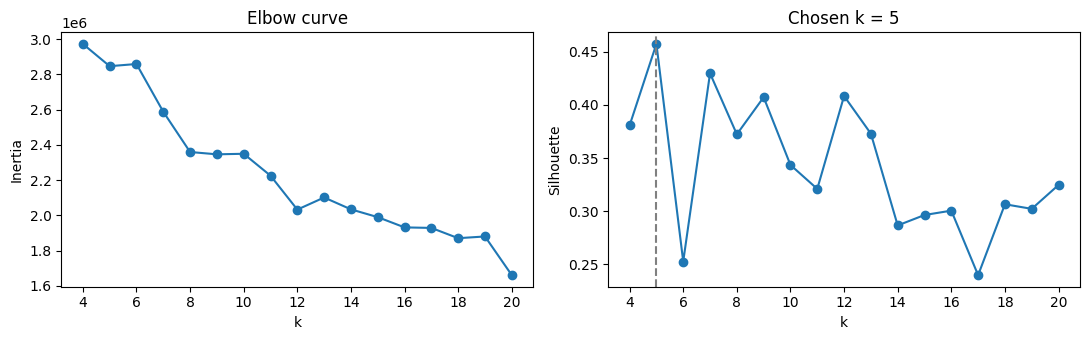

Test set: purity 0.7302 | ARI 0.3719 | NMI 0.4058


family,Normal,DoS,Probe,R2L,U2R
cluster,,,,,
0,153,12,1521,28,0
1,9164,2026,30,2309,48
2,2,1891,221,1,0
3,67,3457,384,118,0
4,325,74,265,429,19


In [32]:
silhouette_rows = np.random.default_rng(SEED).choice(len(train), size=4000, replace=False)
cluster_candidates, cluster_selection = {}, []
for k in range(4, 21):
    km = MiniBatchKMeans(n_clusters=k, batch_size=4096, n_init=3, random_state=SEED).fit(Ztr)
    score = silhouette_score(Ztr[silhouette_rows], km.predict(Ztr[silhouette_rows]))
    cluster_candidates[k] = km
    cluster_selection.append({"k": k, "inertia": float(km.inertia_), "silhouette": float(score)})
cluster_selection = pd.DataFrame(cluster_selection)
chosen_k = int(cluster_selection.loc[cluster_selection["silhouette"].idxmax(), "k"])
cluster_model = cluster_candidates[chosen_k]
cluster_tr, cluster_te = cluster_model.predict(Ztr), cluster_model.predict(Zte)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(cluster_selection["k"], cluster_selection["inertia"], marker="o")
axes[0].set(xlabel="k", ylabel="Inertia", title="Elbow curve")
axes[1].plot(cluster_selection["k"], cluster_selection["silhouette"], marker="o")
axes[1].axvline(chosen_k, ls="--", color="grey")
axes[1].set(xlabel="k", ylabel="Silhouette", title=f"Chosen k = {chosen_k}")
plt.tight_layout()
plt.show()

composition = pd.crosstab(pd.Series(cluster_te, name="cluster"), pd.Series(yte, name="family")).reindex(columns=CLASSES, fill_value=0)
cluster_purity = composition.max(axis=1).sum() / len(test)
print(f"Test set: purity {cluster_purity:.4f} | ARI {adjusted_rand_score(yte, cluster_te):.4f} | "
      f"NMI {normalized_mutual_info_score(yte, cluster_te):.4f}")
display(composition)

*Source: Repo `05` (distance-to-centroid outliers), now tested on `KDDTest+`.* A row is flagged if its distance to its cluster centre is above the 95th percentile of training distances. "Lift" compares the attack share among flagged rows with the overall attack share.

In [33]:
train_distance = cluster_model.transform(Ztr).min(axis=1)
test_distance = cluster_model.transform(Zte).min(axis=1)
distance_flag = test_distance > np.percentile(train_distance, 95)
attack_share_flagged = np.mean(yte[distance_flag] != "Normal")
print(f"Flagged test rows: {distance_flag.mean():.3f} | attacks among flagged: {attack_share_flagged:.3f} | "
      f"base attack rate: {np.mean(yte != 'Normal'):.3f} | lift {attack_share_flagged / np.mean(yte != 'Normal'):.2f}x")
print("Distance to a centre fitted on ALL traffic is a weak alarm. The detectors in Task 17 learn Normal traffic only.")

Flagged test rows: 0.091 | attacks among flagged: 0.905 | base attack rate: 0.569 | lift 1.59x
Distance to a centre fitted on ALL traffic is a weak alarm. The detectors in Task 17 learn Normal traffic only.


## Task 17 — Optional High-Recall Mode: Normal-Only Anomaly Detection
*Source: IDS_Final (§7, §12A, §12E-3).* Three detectors learn **only Normal** traffic: Isolation Forest, distance to Normal k-means centres, and kNN distance. A connection is flagged if the classifier says attack **or** its anomaly score is high. Flagged rows the classifier can't name become `Unknown attack`.
- The detector and the naming cutoff are chosen on the leave-attack-type-out folds, and the alarm thresholds come from held-out training Normal (2% and 5% budgets).
- This mode catches more unseen attacks but adds false alarms, which costs accuracy and precision. That's why it's optional.

In [34]:
FA_BUDGETS = [0.02, 0.05, 0.10]
DETECTORS = ["Isolation forest", "Centroid distance", "kNN distance"]
ANOMALY_CANDIDATES = DETECTORS + ["Mean of three"]


def fit_anomaly_scorers(normal_space, seed):
    iso = IsolationForest(n_estimators=200, n_jobs=CPU_THREADS, random_state=seed).fit(normal_space)
    cen = MiniBatchKMeans(n_clusters=chosen_k, n_init=3, batch_size=4096, random_state=seed).fit(normal_space)
    return {"Isolation forest": lambda Z: -iso.score_samples(Z),
            "Centroid distance": lambda Z: cen.transform(Z).min(axis=1),
            "kNN distance": fit_knn(normal_space, seed)}


def split_normal(rows, seed, holdout=0.15):
    rows = np.random.default_rng(seed).permutation(rows)
    cut = int(round(holdout * len(rows)))
    return rows[cut:], rows[:cut]


def normal_percentile(reference, values):
    # share of held-out Normal scores at or below each value
    return np.searchsorted(np.sort(reference), values, side="right") / len(reference)


def anomaly_percentiles(scorers, Z_reference, Z_target):
    out = {}
    for name in DETECTORS:
        ref = scorers[name](Z_reference)
        out[name] = (normal_percentile(ref, ref), normal_percentile(ref, scorers[name](Z_target)))
    out["Mean of three"] = tuple(np.mean([out[n][i] for n in DETECTORS], axis=0) for i in (0, 1))
    return out


def fuse_with_classifier(anomaly_ref, anomaly_target, alarm_ref, alarm_target):
    # classifier alarms rank above every anomaly score, so one threshold sets the total false-alarm budget
    return (np.where(alarm_ref, 1 + anomaly_ref, anomaly_ref),
            np.where(alarm_target, 1 + anomaly_target, anomaly_target))


def budget_threshold(reference_scores, budget):
    return float(np.quantile(reference_scores, 1 - budget))


# --- choose the detector on the folds (validation attacks are unseen techniques) ---
af_rows, af_fold_cache = [], []
for f in range(FOLDS):
    fit_rows, val_rows = np.flatnonzero(fold_id != f), np.flatnonzero(fold_id == f)
    nf, nh = split_normal(fit_rows[ytr[fit_rows] == "Normal"], SEED + f)
    pct = anomaly_percentiles(fit_anomaly_scorers(Ztr[nf], SEED + f), Ztr[nh], Ztr[val_rows])
    af_fold_cache.append((val_rows, nh, pct))
    for name in ANOMALY_CANDIDATES:
        for budget in FA_BUDGETS:
            alerts = pct[name][1] > budget_threshold(pct[name][0], budget)
            truth = ytr[val_rows]
            af_rows.append({"score": name, "budget": budget,
                            "attack_detection": np.mean(alerts[truth != "Normal"]),
                            "normal_fpr": np.mean(alerts[truth == "Normal"])})
af_choice = pd.DataFrame(af_rows).groupby(["score", "budget"])[["attack_detection", "normal_fpr"]].mean().unstack("budget")
AF_SCORE = af_choice["attack_detection"].mean(axis=1).idxmax()
display(af_choice.round(4))
print("FROZEN ANOMALY SCORE:", AF_SCORE)

attack_detection                 normal_fpr                
budget                        0.02    0.05    0.10       0.02    0.05    0.10
score                                                                        
Centroid distance           0.1987  0.6336  0.7641     0.0199  0.0507  0.1006
Isolation forest            0.5086  0.6352  0.7357     0.0204  0.0511  0.0979
Mean of three               0.6906  0.8094  0.8924     0.0202  0.0486  0.0984
kNN distance                0.8189  0.8998  0.9367     0.0202  0.0493  0.0994

FROZEN ANOMALY SCORE: kNN distance


The naming cutoff is chosen for the whole pipeline (alert → name or Unknown → second stage) to maximise validation macro F1 over the four attack families.

In [35]:
def high_recall_labels(alerts, scores, cutoff, s2_fire, s2_fam):
    family_ = to_family(scores).astype(object)
    named = alerts & (family_ != "Normal") & (scores.max(axis=1) >= cutoff)
    labels = np.where(~alerts, "Normal", np.where(named, family_, "Unknown attack")).astype(object)
    labels[s2_fire] = s2_fam[s2_fire]
    return labels


naming_rows = []
for val_rows, nh, pct in af_fold_cache:
    fused_ref, fused_val = fuse_with_classifier(pct[AF_SCORE][0], pct[AF_SCORE][1],
                                                oof_family[nh] != "Normal", oof_family[val_rows] != "Normal")
    alerts = fused_val > budget_threshold(fused_ref, 0.05)
    for cutoff in np.round(np.arange(0.30, 0.96, 0.05), 2):
        labels = high_recall_labels(alerts, oof_scores[SELECTED_NAME][val_rows], cutoff,
                                    fire_val[val_rows], oof_s2_family[val_rows])
        naming_rows.append({"cutoff": cutoff, "macro_f1_attack_families": f1_score(
            ytr[val_rows], labels, labels=ATTACK_FAMILIES, average="macro", zero_division=0)})
NAMING_CUTOFF = float(pd.DataFrame(naming_rows).groupby("cutoff")["macro_f1_attack_families"].mean().idxmax())
print("FROZEN naming cutoff:", NAMING_CUTOFF)

# --- final detector: fitted on training Normal, thresholds from held-out training Normal ---
af_fit, af_hold = split_normal(np.flatnonzero(ytr == "Normal"), SEED)
af_pct = anomaly_percentiles(fit_anomaly_scorers(Ztr[af_fit], SEED), Ztr[af_hold], Zte)
anomaly_ref, anomaly_test = af_pct[AF_SCORE]
fused_ref, fused_test = fuse_with_classifier(anomaly_ref, anomaly_test,
                                             oof_family[af_hold] != "Normal", primary_prediction != "Normal")

high_recall = {}
for budget in [0.02, 0.05]:
    alerts = fused_test > budget_threshold(fused_ref, budget)
    high_recall[budget] = high_recall_labels(alerts, primary_scores, NAMING_CUTOFF, stage2_fire, s2_family)
high_recall_score = np.where(stage2_fire, np.maximum(fused_test, 1 + s2_test), fused_test)

print("High-recall mode (5% budget): true family x output")
display(pd.crosstab(pd.Series(yte, name="true family"),
                    pd.Series(pd.Categorical(high_recall[0.05], categories=CLASSES + ["Unknown attack"]), name="output"),
                    dropna=False).reindex(index=CLASSES))

FROZEN naming cutoff: 0.3


High-recall mode (5% budget): true family x output


output,Normal,DoS,Probe,R2L,U2R,Unknown attack
true family,,,,,,
Normal,9088,60,217,17,9,320
DoS,204,5865,176,157,0,1058
Probe,3,166,1971,7,0,274
R2L,1287,0,40,1319,16,223
U2R,9,0,1,13,28,16


## Task 18 — Final Comparison on KDDTest+
*Source: both.* Weaker approaches appear only as rows here (the full candidate list is in Task 12). All systems are scored on the same test file. ★ marks the best value for each metric (lowest for false alarms). `Unknown attack` counts as wrong for accuracy and F1. *Unseen* = the 17 attack types that never appear in training.

In [36]:
def unseen_detection(predicted):
    return float(np.mean(np.asarray(predicted)[novel_mask] != "Normal"))


systems = [
    ("Repo: tuned RF + hierarchical RF", repo_test_pred, repo_test_attack_proba),
    ("Repo: XGBoost multiclass", to_family(repo_xgb_scores), 1 - repo_xgb_scores[:, 0]),
    (f"Classifier alone ({SELECTED_NAME})" + (" = PRIMARY" if PRIMARY_MODE == "Classifier alone" else ""),
     primary_prediction, 1 - primary_scores[:, 0]),
    ("Classifier + R2L/U2R second stage" + (" = PRIMARY" if PRIMARY_MODE != "Classifier alone" else ""),
     with_stage2_prediction, with_stage2_score),
    ("Optional high-recall mode, 2% budget", high_recall[0.02], high_recall_score),
    ("Optional high-recall mode, 5% budget (= IDS_Final final)", high_recall[0.05], high_recall_score),
]
final_rows = []
for name, predicted, score in systems:
    row = summary_row(name, yte, predicted, score)
    row["unseen_detection"] = unseen_detection(predicted)
    final_rows.append(row)
final_table = pd.DataFrame(final_rows).set_index("model")
final_table = final_table[["accuracy", "macro_f1", "weighted_f1", "macro_precision", "attack_precision",
                           "attack_detection", "normal_fpr", "unseen_detection", "R2L_recall", "U2R_recall",
                           "roc_auc", "pr_auc"]]

marked = final_table.round(4).astype(str)
for metric in final_table.columns:
    best_value = final_table[metric].min() if metric == "normal_fpr" else final_table[metric].max()
    is_best = np.isclose(final_table[metric], best_value)
    marked.loc[is_best, metric] = marked.loc[is_best, metric] + " ★"

with pd.option_context("display.max_columns", None, "display.width", 250):
    display(marked.T)

final_table.round(4).to_csv("../results/ids_nsl_kdd_final_comparison.csv")

model,Repo: tuned RF + hierarchical RF,Repo: XGBoost multiclass,Classifier alone (Gradient boosting (class-weighted)) = PRIMARY,Classifier + R2L/U2R second stage,"Optional high-recall mode, 2% budget","Optional high-recall mode, 5% budget (= IDS_Final final)"
accuracy,0.7968,0.7802,0.8024,0.8247 ★,0.8219,0.8105
macro_f1,0.5959,0.5541,0.6861,0.7194,0.726,0.7288 ★
weighted_f1,0.7617,0.743,0.7857,0.8175,0.8319,0.838 ★
macro_precision,0.8322 ★,0.8168,0.8302,0.7872,0.799,0.8081
attack_precision,0.9688,0.9687,0.9693,0.9699 ★,0.967,0.9479
attack_detection,0.6954,0.6603,0.7061,0.7605,0.8318,0.8829 ★
normal_fpr,0.0296,0.0282 ★,0.0296,0.0312,0.0375,0.0642
unseen_detection,0.472,0.3675,0.3808,0.42,0.6475,0.7925 ★
R2L_recall,0.1036,0.086,0.2787,0.4572 ★,0.4572 ★,0.4572 ★
U2R_recall,0.1642,0.1045,0.3881,0.4179 ★,0.4179 ★,0.4179 ★


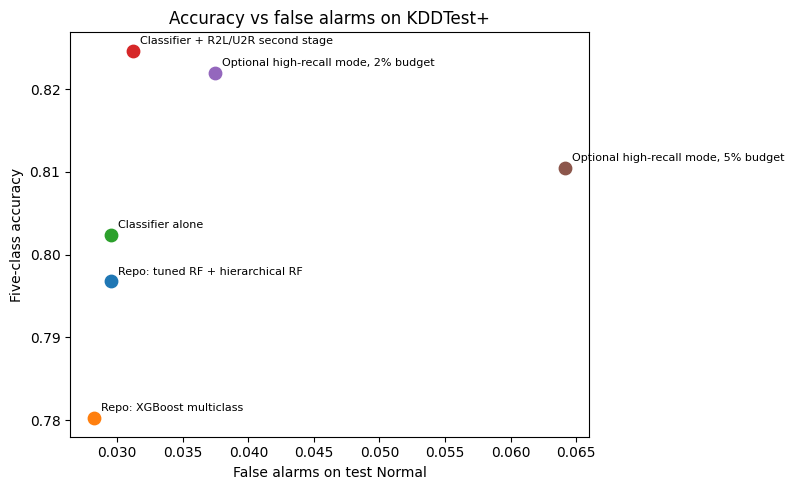

In [37]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, row in final_table.iterrows():
    ax.scatter(row["normal_fpr"], row["accuracy"], s=80)
    ax.annotate(name.split(" (")[0], (row["normal_fpr"], row["accuracy"]), textcoords="offset points",
                xytext=(5, 5), fontsize=8)
ax.set(xlabel="False alarms on test Normal", ylabel="Five-class accuracy",
       title="Accuracy vs false alarms on KDDTest+")
plt.tight_layout()
plt.savefig("../results/ids_nsl_kdd_accuracy_vs_false_alarms.png", dpi=120)
plt.show()

*Source: IDS_Final (§5 per-technique table, §12 seen/unseen split).* Detection split into techniques seen in training vs the 17 test-only ones, and per attack type. Unseen techniques are where every supervised system loses most.

In [38]:
seen_rows = []
attack_mask = yte != "Normal"
for name, predicted in [("Primary", best_prediction), ("Classifier + second stage", with_stage2_prediction),
                        ("High-recall 2%", high_recall[0.02]), ("High-recall 5%", high_recall[0.05])]:
    flagged = np.asarray(predicted) != "Normal"
    correct = np.asarray(predicted) == yte
    for group, mask in [("seen techniques", attack_mask & ~novel_mask), ("unseen techniques", novel_mask)]:
        seen_rows.append({"system": name, "group": group, "rows": int(mask.sum()),
                          "flagged_as_attack": flagged[mask].mean(), "correct_family": correct[mask].mean()})
display(pd.DataFrame(seen_rows).pivot(index="system", columns="group", values=["flagged_as_attack", "correct_family"]).round(3))

per_attack = pd.DataFrame({"attack": test["label"], "family": yte, "unseen": novel_mask,
                           "primary_flagged": best_prediction != "Normal",
                           "primary_correct": best_prediction == yte,
                           "high_recall_5%_flagged": high_recall[0.05] != "Normal"})[attack_mask]
per_attack = per_attack.groupby(["family", "attack"]).agg(
    test_rows=("unseen", "size"), unseen=("unseen", "first"), primary_flagged=("primary_flagged", "mean"),
    primary_correct=("primary_correct", "mean"), high_recall_5_flagged=("high_recall_5%_flagged", "mean"))
print("Per attack type on KDDTest+ (sorted by size):")
display(per_attack.sort_values("test_rows", ascending=False).round(3))
per_attack.round(4).to_csv("../results/ids_nsl_kdd_per_attack_breakdown.csv")

flagged_as_attack                    correct_family                  
group                       seen techniques unseen techniques seen techniques unseen techniques
system                                                                                         
Classifier + second stage             0.901             0.420           0.891             0.290
High-recall 2%                        0.908             0.647           0.891             0.290
High-recall 5%                        0.920             0.793           0.891             0.290
Primary                               0.840             0.381           0.835             0.289

Per attack type on KDDTest+ (sorted by size):


test_rows  unseen  primary_flagged  primary_correct  high_recall_5_flagged
family attack                                                                                     
DoS    neptune               4657   False            0.993            0.984                  1.000
R2L    guess_passwd          1231   False            0.051            0.051                  0.462
Probe  mscan                  996    True            0.719            0.552                  1.000
R2L    warezmaster            944   False            0.779            0.779                  0.948
DoS    apache2                737    True            0.278            0.278                  0.985
Probe  satan                  735   False            1.000            1.000                  1.000
DoS    processtable           685    True            0.194            0.000                  1.000
       smurf                  665   False            1.000            1.000                  1.000
       back                   359   False            1.000            1.000                  1.000
R2L    snmpguess              331    True            0.003            0.000                  0.018
Probe  saint                  319    True            0.987            0.987                  0.991
DoS    mailbomb               293    True            0.000            0.000                  0.362
R2L    snmpgetattack          178    True            0.000            0.000                  0.039
Probe  portsweep              157   False            1.000            1.000                  1.000
       ipsweep                141   False            1.000            1.000                  1.000
R2L    httptunnel             133    True            0.256            0.000                  0.481
Probe  nmap                    73   False            1.000            1.000                  1.000
DoS    pod                     41   False            0.902            0.878                  0.902
U2R    buffer_overflow         20   False            0.500            0.450                  1.000
R2L    multihop                18   False            0.389            0.111                  0.722
       named                   17    True            0.353            0.059                  0.941
U2R    ps                      15    True            0.467            0.333                  0.733
R2L    sendmail                14    True            0.071            0.000                  0.714
U2R    xterm                   13    True            0.462            0.385                  0.923
       rootkit                 13   False            0.385            0.308                  0.692
DoS    teardrop                12   False            1.000            1.000                  1.000
R2L    xlock                    9    True            0.000            0.000                  1.000
DoS    land                     7   False            0.714            0.714                  1.000
R2L    xsnoop                   4    True            0.250            0.000                  1.000
       ftp_write                3   False            0.333            0.333                  0.667
       phf                      2   False            0.500            0.500                  1.000
DoS    worm                     2    True            0.000            0.000                  0.000
       udpstorm                 2    True            1.000            0.000                  1.000
U2R    perl                     2   False            1.000            1.000                  1.000
       loadmodule               2   False            0.000            0.000                  1.000
       sqlattack                2    True            0.500            0.500                  1.000
R2L    imap                     1   False            1.000            1.000                  1.000

**Reading the table.** The primary system was frozen on validation, before this table. On the validation folds R2L is under 1% of rows, so the second stage could not raise validation accuracy. On `KDDTest+` R2L is about 13% of rows, so the rows that re-label missed R2L also raise test accuracy. This gap is itself the data limitation of Task 19: training data does not show the test set's attack mix.

## Task 19 — Why R2L and U2R Stay Weak (Data Limitation)
- **Very little to learn from:** 995 R2L and 52 U2R training rows, against 67k Normal.
- **Different attacks in test:** most test R2L/U2R rows are techniques that are rare or **absent** in training (`snmpguess`, `snmpgetattack`, `httptunnel`, `mscan`-era attacks...). A supervised model can't name what it has never seen.
- **They look normal:** single, ordinary-looking login sessions (`SF` TCP), so connection features barely separate them from Normal.
- **Drift:** Normal traffic itself shifts between train and test (Task 5), so tighter thresholds would cost precision.

So we optimise accuracy and precision and accept lower R2L/U2R recall. The optional high-recall mode shows how many more of them can be *flagged* if the extra false alarms are acceptable.

In [39]:
weak_rows = []
for fam in ["R2L", "U2R"]:
    mask = yte == fam
    weak_rows.append({"family": fam, "train_rows": int((ytr == fam).sum()), "test_rows": int(mask.sum()),
                      "test_rows_from_unseen_techniques": float(np.mean(novel_mask[mask])),
                      "primary_recall": float(np.mean(best_prediction[mask] == fam)),
                      "high_recall_mode_flagged": float(np.mean(high_recall[0.05][mask] != "Normal"))})
display(pd.DataFrame(weak_rows).round(3))


def wilson_interval(successes, n, z=1.96):
    # 95% interval for a proportion; honest for small n like U2R (67 test rows)
    p = successes / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


for fam in ["R2L", "U2R"]:
    mask = yte == fam
    hits = int(np.sum(best_prediction[mask] == fam))
    low, high = wilson_interval(hits, int(mask.sum()))
    print(f"{fam} recall (primary): {hits}/{mask.sum()} = {hits / mask.sum():.3f}, 95% Wilson CI [{low:.3f}, {high:.3f}]")

,family,train_rows,test_rows,test_rows_from_unseen_techniques,primary_recall,high_recall_mode_flagged
0,R2L,995,2885,0.238,0.279,0.554
1,U2R,52,67,0.448,0.388,0.866


R2L recall (primary): 804/2885 = 0.279, 95% Wilson CI [0.263, 0.295]
U2R recall (primary): 26/67 = 0.388, 95% Wilson CI [0.280, 0.508]


## Task 20 — Risk Classification and Decision Support
*Source: IDS_Final (§12 policy).* **Normal → Low, Probe → Medium, DoS → High, R2L/U2R → Critical, Unknown attack → High.** R2L/U2R mean someone got into a host, so they are Critical. This is an operational rule for ordering analyst reviews, not a dataset label.

In [40]:
RISK_POLICY = {"Normal": "Low", "Probe": "Medium", "DoS": "High",
               "R2L": "Critical", "U2R": "Critical", "Unknown attack": "High"}
RISK_ORDER = ["Low", "Medium", "High", "Critical"]


def classify_connections(connection_frame):
    # raw NSL-KDD records in -> family, risk tier and scores out (primary system)
    features = engineer(connection_frame)
    X = build_matrix(features)
    if USE_TARGET_ENCODING:
        X = np.hstack([X, service_encoding(train["service"], ytr, features["service"])])
    scores = predict_scores(final_models[SELECTED_NAME], X)
    predicted = to_family(scores).astype(object)
    if PRIMARY_MODE != "Classifier alone":
        z = traffic_scaler.transform(traffic_space(features)).astype(np.float32)
        b = behaviour_matrix(features, BEHAVIOUR_V1 if S2_VERSION == "v1" else BEHAVIOUR_V2, np.log1p(full_knn(z)))
        attack_score, u2r_share = stage2_outputs(stage2_model, b)
        fire = (predicted == "Normal") & (attack_score >= S2_THRESHOLD)
        predicted[fire] = np.where(u2r_share[fire] >= U2R_SHARE_CUTOFF, "U2R", "R2L")
    return pd.DataFrame({"predicted_family": predicted,
                         "risk_tier": [RISK_POLICY[p] for p in predicted],
                         "attack_probability": 1 - scores[:, 0]}, index=connection_frame.index)


risk_output = classify_connections(test_df[column_names])
assert np.array_equal(risk_output["predicted_family"].to_numpy(), best_prediction)

for name, predicted in [("Primary system", best_prediction), ("High-recall mode (5%)", high_recall[0.05])]:
    tiers = pd.Categorical([RISK_POLICY[p] for p in predicted], categories=RISK_ORDER)
    table = pd.crosstab(pd.Series(yte, name="true family"), pd.Series(tiers, name="risk tier"), dropna=False).reindex(index=CLASSES)
    high = np.isin(np.asarray(tiers), ["High", "Critical"])
    print(f"{name}: {np.mean(high[yte != 'Normal']):.1%} of attacks are High/Critical vs "
          f"{np.mean(high[yte == 'Normal']):.1%} of Normal")
    display(table)

batch = test_df[column_names].iloc[:5000]
timings = []
for _ in range(3):
    start = time.perf_counter()
    classify_connections(batch)
    timings.append(time.perf_counter() - start)
print(f"Offline throughput: {len(batch) / np.median(timings):,.0f} connections/second "
      "(model only; no packet capture)")

Primary system: 53.6% of attacks are High/Critical vs 0.7% of Normal


risk tier,Low,Medium,High,Critical
true family,,,,
Normal,9424,217,60,10
DoS,1417,176,5865,2
Probe,284,1971,166,0
R2L,2034,40,0,811
U2R,36,1,0,30


High-recall mode (5%): 71.2% of attacks are High/Critical vs 4.2% of Normal


risk tier,Low,Medium,High,Critical
true family,,,,
Normal,9088,217,380,26
DoS,204,176,6923,157
Probe,3,1971,440,7
R2L,1287,40,223,1335
U2R,9,1,16,41


Offline throughput: 186,614 connections/second (model only; no packet capture)


## Task 21 — Hidden Markov Model for Multi-Stage Attacks
*Source: IDS_Final (from-scratch categorical HMM: forward/backward, Baum–Welch, Viterbi, checked by brute force) + Repo (`01_eda` Task 13: turn rows into K-means symbols and fixed-length sequences; the repo prepared these but never trained an HMM).*

A multi-stage attack moves through hidden stages (scan → break in → take root). An HMM learns which symbols each stage emits and how stages follow each other. **The key test:** does keeping the order of rows help compared with shuffling them?

In [41]:
class CategoricalHMM:
    """Categorical HMM for a batch of equal-length sequences (log-space, Baum-Welch, Viterbi)."""

    def __init__(self, n_states, n_symbols, seed=42, smoothing=1e-6):
        self.n_states = n_states
        self.n_symbols = n_symbols
        self.seed = seed
        self.smoothing = smoothing

    @staticmethod
    def normalize(values):
        return values / values.sum(axis=-1, keepdims=True)

    def forward(self, x):
        emissions = np.log(self.emission_[:, x]).transpose(1, 2, 0)
        alpha = np.empty_like(emissions)
        log_transition = np.log(self.transition_)
        alpha[:, 0] = np.log(self.start_) + emissions[:, 0]
        for t in range(1, x.shape[1]):
            alpha[:, t] = emissions[:, t] + logsumexp(alpha[:, t - 1, :, None] + log_transition[None], axis=1)
        return alpha, emissions, logsumexp(alpha[:, -1], axis=1)

    def score(self, x):
        return self.forward(np.asarray(x))[2]

    def fit(self, x, max_iter=30, tolerance=1e-4):
        # Baum-Welch (EM)
        x = np.asarray(x)
        rng = np.random.default_rng(self.seed)
        k = self.n_states
        self.start_ = rng.dirichlet(np.ones(k))
        self.transition_ = np.vstack([rng.dirichlet(np.ones(k) + 3 * np.eye(k)[j]) for j in range(k)])
        self.emission_ = rng.dirichlet(np.ones(self.n_symbols), size=k)
        self.history_ = [float(self.score(x).sum())]
        for _ in range(max_iter):
            alpha, emissions, likelihood = self.forward(x)
            beta = np.zeros_like(alpha)
            log_transition = np.log(self.transition_)
            for t in range(x.shape[1] - 2, -1, -1):
                beta[:, t] = logsumexp(log_transition[None] + emissions[:, t + 1, None, :] + beta[:, t + 1, None, :], axis=2)
            gamma = np.exp(alpha + beta - likelihood[:, None, None])
            transitions = np.full((k, k), self.smoothing)
            for t in range(x.shape[1] - 1):
                transitions += np.exp(alpha[:, t, :, None] + log_transition[None] + emissions[:, t + 1, None, :]
                                      + beta[:, t + 1, None, :] - likelihood[:, None, None]).sum(axis=0)
            emission_counts = np.vstack([np.bincount(x.ravel(), weights=gamma[:, :, j].ravel(), minlength=self.n_symbols)
                                         for j in range(k)]) + self.smoothing
            self.start_ = self.normalize(gamma[:, 0].sum(axis=0) + self.smoothing)
            self.transition_ = self.normalize(transitions)
            self.emission_ = self.normalize(emission_counts)
            self.history_.append(float(self.score(x).sum()))
            if (self.history_[-1] - self.history_[-2]) / x.size < tolerance:
                break
        return self

    def fit_supervised(self, x, states):
        # counted (supervised) training when the hidden states are known
        k, s = self.n_states, self.n_symbols
        self.start_ = self.normalize(np.bincount(states[:, 0], minlength=k) + self.smoothing)
        transitions = np.full((k, k), self.smoothing)
        np.add.at(transitions, (states[:, :-1].ravel(), states[:, 1:].ravel()), 1)
        emissions = np.full((k, s), self.smoothing)
        np.add.at(emissions, (states.ravel(), x.ravel()), 1)
        self.transition_ = self.normalize(transitions)
        self.emission_ = self.normalize(emissions)
        self.state_prior_ = self.normalize(np.bincount(states.ravel(), minlength=k) + self.smoothing)
        return self

    def decode(self, x):
        # Viterbi
        x = np.asarray(x)
        emissions = np.log(self.emission_[:, x]).transpose(1, 2, 0)
        n, length = x.shape
        delta = np.log(self.start_) + emissions[:, 0]
        previous = np.zeros((n, length, self.n_states), dtype=np.int64)
        for t in range(1, length):
            scores = delta[:, :, None] + np.log(self.transition_)[None]
            previous[:, t] = scores.argmax(axis=1)
            delta = scores.max(axis=1) + emissions[:, t]
        path = np.empty((n, length), dtype=np.int64)
        path[:, -1] = delta.argmax(axis=1)
        for t in range(length - 1, 0, -1):
            path[:, t - 1] = previous[np.arange(n), t, path[:, t]]
        return path

    def emission_only(self, x):
        # judge each step alone, ignoring transitions (control)
        return (np.log(self.emission_[:, np.asarray(x)]) + np.log(self.state_prior_)[:, None, None]).argmax(axis=0)

Check the maths against brute force over every state path, and check that Baum–Welch never lowers the likelihood.

In [42]:
import itertools

check = CategoricalHMM(2, 2)
check.start_ = np.array([0.6, 0.4])
check.transition_ = np.array([[0.7, 0.3], [0.2, 0.8]])
check.emission_ = np.array([[0.9, 0.1], [0.3, 0.7]])
toy = np.array([[0, 1, 1], [1, 0, 1]])
for sequence, likelihood, path in zip(toy, np.exp(check.score(toy)), check.decode(toy)):
    probabilities = {}
    for states in itertools.product(range(2), repeat=len(sequence)):
        p = check.start_[states[0]] * check.emission_[states[0], sequence[0]]
        for t in range(1, len(sequence)):
            p *= check.transition_[states[t - 1], states[t]] * check.emission_[states[t], sequence[t]]
        probabilities[states] = p
    assert np.isclose(likelihood, sum(probabilities.values()))
    assert tuple(path) == max(probabilities, key=probabilities.get)

em = CategoricalHMM(2, 3).fit(np.random.default_rng(SEED).integers(0, 3, size=(25, 12)), max_iter=12)
assert np.diff(em.history_).min() >= -1e-6
print("HMM checks passed: forward likelihood and Viterbi match brute force; Baum-Welch likelihood never decreases.")

HMM checks passed: forward likelihood and Viterbi match brute force; Baum-Welch likelihood never decreases.


**The NSL-KDD test.** NSL-KDD has no timestamps and no host addresses, so the only "order" is the row order in the file. Rows are cut into 20-row windows (states = the 5 families, symbols = the Task 16 cluster ids). The HMM decodes test windows three ways: in file order, after shuffling, and with emission-only (no transitions). We also repeat this with the repo's setup (20 K-means symbols, 10-row windows).

In [43]:
state_index = {label: i for i, label in enumerate(CLASSES)}
shuffle_order = np.random.default_rng(SEED).permutation(len(test))


def to_windows(values, length):
    values = np.asarray(values)
    usable = len(values) // length * length
    return values[:usable].reshape(-1, length)


def hmm_order_test(symbols_tr, symbols_te, n_symbols, length):
    states_tr = to_windows(pd.Series(ytr).map(state_index).to_numpy(), length)
    states_te = to_windows(pd.Series(yte).map(state_index).to_numpy(), length)
    hmm = CategoricalHMM(len(CLASSES), n_symbols, smoothing=0.5).fit_supervised(to_windows(symbols_tr, length), states_tr)
    shuffled_states = to_windows(pd.Series(yte[shuffle_order]).map(state_index).to_numpy(), length)
    rows = hmm.transition_
    return hmm, {
        "file_order_accuracy": accuracy_score(states_te.ravel(), hmm.decode(to_windows(symbols_te, length)).ravel()),
        "shuffled_order_accuracy": accuracy_score(shuffled_states.ravel(),
                                                  hmm.decode(to_windows(symbols_te[shuffle_order], length)).ravel()),
        "emission_only_accuracy": accuracy_score(states_te.ravel(), hmm.emission_only(to_windows(symbols_te, length)).ravel()),
        "mean_transition_row_L1_distance": float(np.mean([np.abs(rows[i] - rows[j]).sum()
                                                         for i in range(len(rows)) for j in range(i + 1, len(rows))])),
    }


nsl_hmm, hmm_result = hmm_order_test(cluster_tr, cluster_te, chosen_k, 20)

repo_km = MiniBatchKMeans(n_clusters=20, batch_size=4096, n_init=3, random_state=SEED).fit(Ztr)
_, hmm_result_repo = hmm_order_test(repo_km.predict(Ztr), repo_km.predict(Zte), 20, 10)

hmm_table = pd.DataFrame([{"setup": f"IDS_Final: {chosen_k} symbols, 20-row windows", **hmm_result},
                          {"setup": "Repo: 20 symbols, 10-row windows", **hmm_result_repo}])
display(hmm_table.round(4))

print("Transition matrix P(next family | current family) in file order:")
display(pd.DataFrame(nsl_hmm.transition_, index=CLASSES, columns=CLASSES).round(3))

,setup,file_order_accuracy,shuffled_order_accuracy,emission_only_accuracy,mean_transition_row_L1_distance
0,"IDS_Final: 5 symbols, 20-row windows",0.7229,0.7229,0.7229,0.0438
1,"Repo: 20 symbols, 10-row windows",0.7082,0.7082,0.7082,0.0457


Transition matrix P(next family | current family) in file order:


,Normal,DoS,Probe,R2L,U2R
Normal,0.534,0.366,0.092,0.008,0.000
DoS,0.535,0.363,0.093,0.008,0.000
Probe,0.534,0.365,0.093,0.008,0.000
R2L,0.512,0.380,0.091,0.015,0.001
U2R,0.495,0.379,0.107,0.010,0.010


**Control: does the HMM work when order really exists?** *Source: IDS_Final §10.* **SIMULATED sequences, not real sessions:** a known kill chain Normal → Probe → R2L → U2R (half the sequences stay Normal), each step a real NSL-KDD record shown by its cluster id. Train chains use `KDDTrain+` records, test chains use `KDDTest+` records.

In [44]:
SIMULATED_STAGES = ["Normal", "Probe", "R2L", "U2R"]


def simulated_sequences(labels, symbols, count, seed):
    rng = np.random.default_rng(seed)
    labels = np.asarray(labels)
    pools = {label: np.flatnonzero(labels == label) for label in SIMULATED_STAGES}
    observations, states_list = [], []
    for i in range(count):
        if i % 2 == 0:
            states = np.zeros(40, dtype=np.int64)
        else:
            durations = 5 + rng.multinomial(20, np.full(4, 0.25))
            states = np.repeat(np.arange(4), durations)
        rows = np.array([rng.choice(pools[SIMULATED_STAGES[s]]) for s in states])
        observations.append(symbols[rows])
        states_list.append(states)
    return np.asarray(observations), np.asarray(states_list)


sim_train_x, sim_train_y = simulated_sequences(ytr, cluster_tr, 300, SEED)
sim_test_x, sim_test_y = simulated_sequences(yte, cluster_te, 300, SEED + 1)
sim_hmm = CategoricalHMM(4, chosen_k, smoothing=0.1).fit_supervised(sim_train_x, sim_train_y)

permutation = np.argsort(np.random.default_rng(SEED).random(sim_test_x.shape), axis=1)
sim_shuffled_x = np.take_along_axis(sim_test_x, permutation, axis=1)
sim_shuffled_y = np.take_along_axis(sim_test_y, permutation, axis=1)

simulation_results = pd.DataFrame([
    {"model": "HMM, ordered", "accuracy": accuracy_score(sim_test_y.ravel(), sim_hmm.decode(sim_test_x).ravel())},
    {"model": "Emission only", "accuracy": accuracy_score(sim_test_y.ravel(), sim_hmm.emission_only(sim_test_x).ravel())},
    {"model": "HMM, shuffled", "accuracy": accuracy_score(sim_shuffled_y.ravel(), sim_hmm.decode(sim_shuffled_x).ravel())},
])
print("SIMULATED kill chain (control):")
display(simulation_results.round(4))

SIMULATED kill chain (control):


,model,accuracy
0,"HMM, ordered",0.8702
1,Emission only,0.7035
2,"HMM, shuffled",0.6410


### Why does the HMM fail? Four checks with graphs
The tables above show *that* the HMM gains nothing on NSL-KDD. The next cells show *why*. First, all the cases side by side: accuracy and macro F1 for both NSL-KDD setups, with the simulated chain as a contrast.

accuracy                                    macro_f1                              
case                                   Emission only HMM, file order HMM, shuffled Emission only HMM, file order HMM, shuffled
setup                                                                                                                         
NSL-KDD (IDS_Final: 5 symbols, 20-row)        0.7229          0.7229        0.7229        0.4508          0.4508        0.4508
NSL-KDD (Repo: 20 symbols, 10-row)            0.7082          0.7082        0.7082        0.4397          0.4397        0.4397
SIMULATED kill chain                          0.7035          0.8702        0.6410        0.4510          0.7223        0.2695

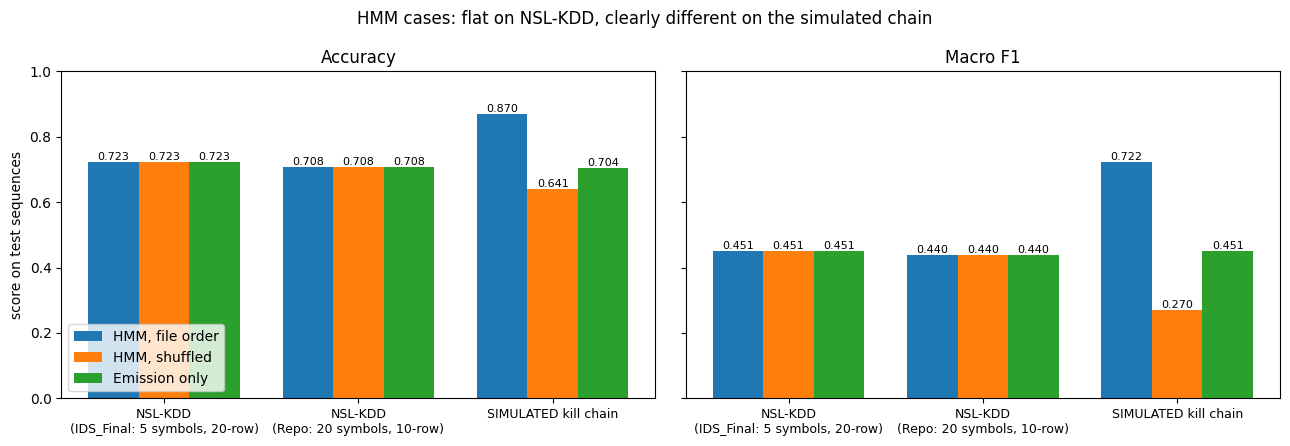

In [45]:
def macro_f1(truth, predicted):
    return f1_score(truth, predicted, average="macro", zero_division=0)


def nsl_case_scores(hmm, symbols_te, length):
    truth = to_windows(pd.Series(yte).map(state_index).to_numpy(), length).ravel()
    truth_shuffled = to_windows(pd.Series(yte[shuffle_order]).map(state_index).to_numpy(), length).ravel()
    cases = {
        "HMM, file order": (truth, hmm.decode(to_windows(symbols_te, length)).ravel()),
        "HMM, shuffled": (truth_shuffled, hmm.decode(to_windows(symbols_te[shuffle_order], length)).ravel()),
        "Emission only": (truth, hmm.emission_only(to_windows(symbols_te, length)).ravel()),
    }
    return {case: (accuracy_score(t, p), macro_f1(t, p)) for case, (t, p) in cases.items()}


repo_symbols_tr, repo_symbols_te = repo_km.predict(Ztr), repo_km.predict(Zte)
repo_hmm, _ = hmm_order_test(repo_symbols_tr, repo_symbols_te, 20, 10)

sim_cases = {
    "HMM, file order": (sim_test_y.ravel(), sim_hmm.decode(sim_test_x).ravel()),
    "HMM, shuffled": (sim_shuffled_y.ravel(), sim_hmm.decode(sim_shuffled_x).ravel()),
    "Emission only": (sim_test_y.ravel(), sim_hmm.emission_only(sim_test_x).ravel()),
}
case_scores = {
    f"NSL-KDD (IDS_Final: {chosen_k} symbols, 20-row)": nsl_case_scores(nsl_hmm, cluster_te, 20),
    "NSL-KDD (Repo: 20 symbols, 10-row)": nsl_case_scores(repo_hmm, repo_symbols_te, 10),
    "SIMULATED kill chain": {case: (accuracy_score(t, p), macro_f1(t, p)) for case, (t, p) in sim_cases.items()},
}
hmm_cases_table = pd.DataFrame([{"setup": setup, "case": case, "accuracy": acc, "macro_f1": f1}
                                for setup, cases in case_scores.items() for case, (acc, f1) in cases.items()])
display(hmm_cases_table.pivot(index="setup", columns="case", values=["accuracy", "macro_f1"]).round(4))

case_names = ["HMM, file order", "HMM, shuffled", "Emission only"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, metric in zip(axes, ["accuracy", "macro_f1"]):
    width = 0.26
    for i, case in enumerate(case_names):
        values = hmm_cases_table[hmm_cases_table["case"] == case].set_index("setup")[metric].reindex(case_scores)
        bars = ax.bar(np.arange(len(case_scores)) + (i - 1) * width, values, width, label=case)
        ax.bar_label(bars, fmt="%.3f", fontsize=8)
    ax.set_xticks(np.arange(len(case_scores)))
    ax.set_xticklabels([s.replace(" (", "\n(") for s in case_scores], fontsize=9)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_ylim(0, 1)
axes[0].set_ylabel("score on test sequences")
axes[0].legend(loc="lower left")
fig.suptitle("HMM cases: flat on NSL-KDD, clearly different on the simulated chain")
plt.tight_layout()
plt.savefig("../results/ids_nsl_kdd_hmm_cases.png", dpi=120)
plt.show()

On both NSL-KDD setups the three bars have the same height, for accuracy and for macro F1. Using the transitions (file order) or destroying the order (shuffled) or dropping transitions completely (emission only) makes no difference. On the simulated chain, where we built in a real order, the ordered HMM is clearly ahead. So the code can use order; NSL-KDD just has none to give.

Max |file - shuffled| over all cells: 0.0273
Frobenius norm of the difference:     0.0425
L1 distance of each file-order row from the class mix (stationary distribution):


,Normal,DoS,Probe,R2L,U2R
L1 to stationary,0.0024,0.0033,0.0024,0.0468,0.0789


,Normal,DoS,Probe,R2L,U2R
class mix in KDDTrain+,0.5346,0.3646,0.0925,0.0079,0.0004


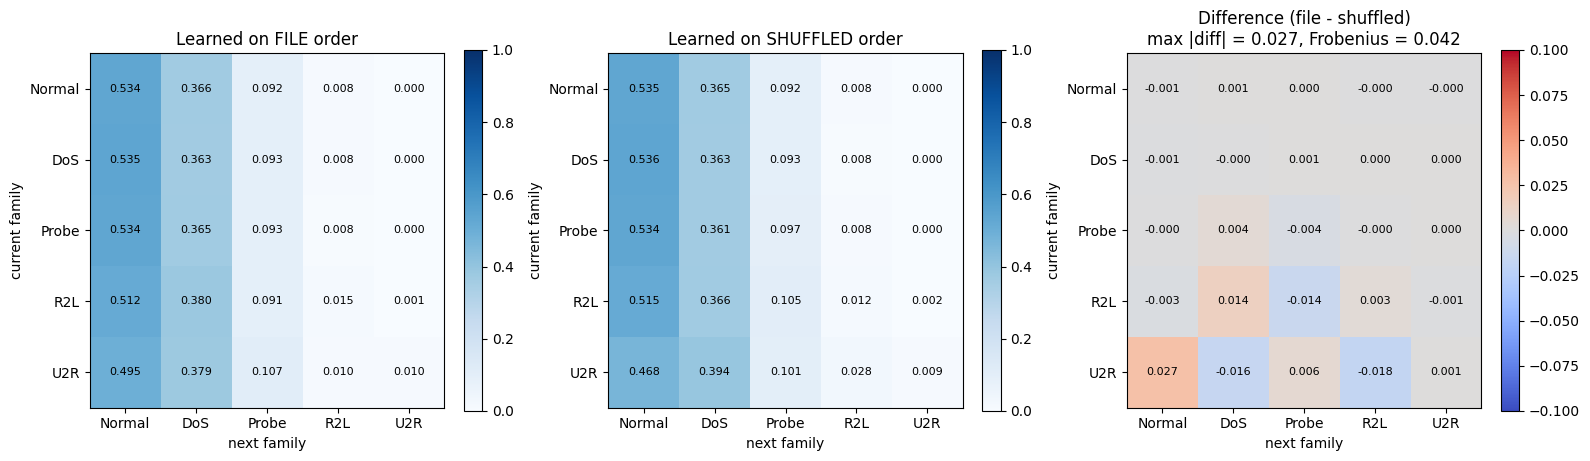

In [46]:
train_states = pd.Series(ytr).map(state_index).to_numpy()
train_shuffle = np.random.default_rng(SEED).permutation(len(train))

hmm_file = CategoricalHMM(len(CLASSES), chosen_k, smoothing=0.5).fit_supervised(
    to_windows(cluster_tr, 20), to_windows(train_states, 20))
hmm_shuffled = CategoricalHMM(len(CLASSES), chosen_k, smoothing=0.5).fit_supervised(
    to_windows(cluster_tr[train_shuffle], 20), to_windows(train_states[train_shuffle], 20))

stationary = np.bincount(train_states, minlength=len(CLASSES)) / len(train_states)
transition_difference = hmm_file.transition_ - hmm_shuffled.transition_
transition_max_abs_diff = float(np.abs(transition_difference).max())
transition_frobenius_diff = float(np.linalg.norm(transition_difference))
row_vs_stationary_l1 = np.abs(hmm_file.transition_ - stationary).sum(axis=1)

print(f"Max |file - shuffled| over all cells: {transition_max_abs_diff:.4f}")
print(f"Frobenius norm of the difference:     {transition_frobenius_diff:.4f}")
print("L1 distance of each file-order row from the class mix (stationary distribution):")
display(pd.Series(row_vs_stationary_l1, index=CLASSES).round(4).to_frame("L1 to stationary").T)
display(pd.Series(stationary, index=CLASSES).round(4).to_frame("class mix in KDDTrain+").T)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
panels = [(hmm_file.transition_, "Learned on FILE order", "Blues", 0, 1),
          (hmm_shuffled.transition_, "Learned on SHUFFLED order", "Blues", 0, 1),
          (transition_difference, "Difference (file - shuffled)", "coolwarm", -0.1, 0.1)]
for ax, (matrix, title, cmap, low, high) in zip(axes, panels):
    image = ax.imshow(matrix, cmap=cmap, vmin=low, vmax=high)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{matrix[i, j]:.3f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(len(CLASSES)))
    ax.set_yticklabels(CLASSES)
    ax.set_xlabel("next family")
    ax.set_ylabel("current family")
    ax.set_title(title)
    plt.colorbar(image, ax=ax, fraction=0.046)
axes[2].set_title(f"Difference (file - shuffled)\nmax |diff| = {transition_max_abs_diff:.3f}, "
                  f"Frobenius = {transition_frobenius_diff:.3f}")
plt.tight_layout()
plt.savefig("../results/ids_nsl_kdd_hmm_transition_matrices.png", dpi=120)
plt.show()

Every row of the file-order transition matrix is close to the same vector, and that vector is just the class mix of `KDDTrain+` (stationary distribution). Whatever the current family is, the guess for the next one is the same, so the model has **no memory**. Shuffling the rows gives almost the same matrix (the difference panel is near zero; the only visible cells are the rare R2L/U2R rows, which rest on very few counts). When every transition row equals the prior, Viterbi reduces to judging each row alone, which is exactly why all three cases score the same.

,MI(label_t; label_t-1) file order (bits),MI(label_t; label_t-1) shuffled (bits),MI(label_t; symbol_t) (bits),attack lag-1 autocorrelation,"attack lag-1 autocorrelation, shuffled"
data,,,,,
KDDTrain+,0.00005,0.00007,0.82523,0.00036,-0.00066
KDDTest+,0.00025,0.00040,0.71071,-0.00819,0.00303


95% noise band for autocorrelation (KDDTrain+): +/-0.0055


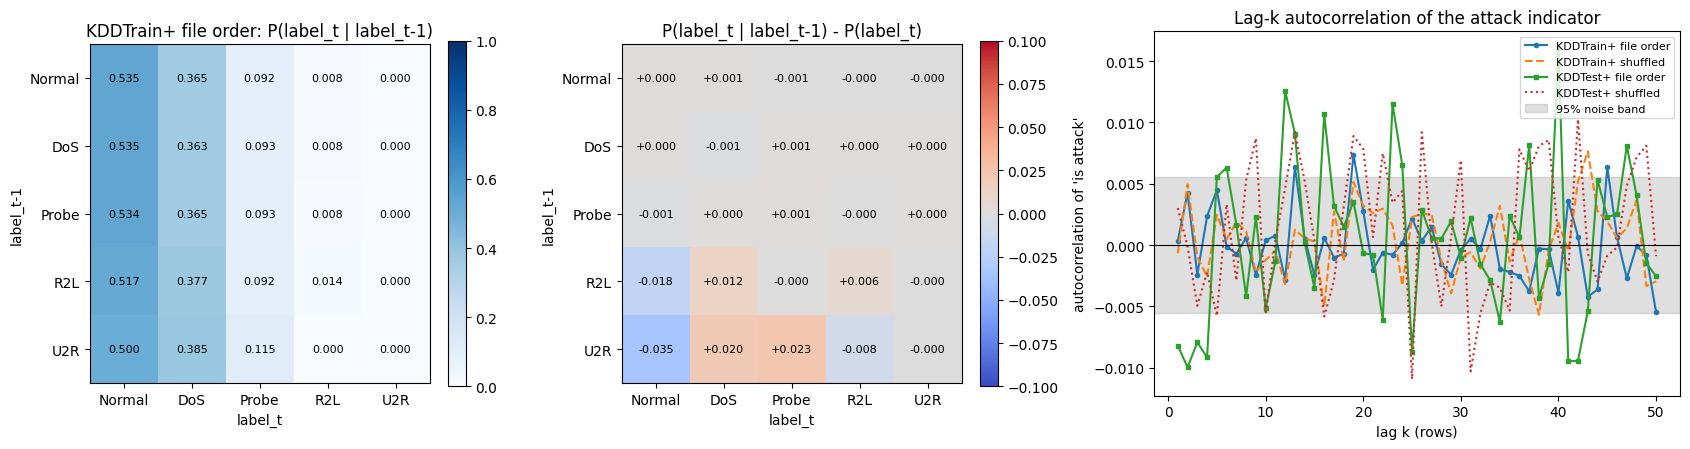

In [47]:
from sklearn.metrics import mutual_info_score


def next_given_current(states):
    counts = np.zeros((len(CLASSES), len(CLASSES)))
    np.add.at(counts, (states[:-1], states[1:]), 1)
    return counts / counts.sum(axis=1, keepdims=True)


def lag_autocorrelation(values, max_lag):
    values = np.asarray(values, dtype=np.float64) - np.mean(values)
    variance = np.dot(values, values)
    return np.array([np.dot(values[:-lag], values[lag:]) / variance for lag in range(1, max_lag + 1)])


MAX_LAG = 50
test_states = pd.Series(yte).map(state_index).to_numpy()
conditional = next_given_current(train_states)
lift = conditional - stationary          # 0 everywhere = the next label ignores the previous one

attack_train = (train_states != state_index["Normal"]).astype(int)
attack_test = (test_states != state_index["Normal"]).astype(int)
acf_rows = {
    "KDDTrain+ file order": lag_autocorrelation(attack_train, MAX_LAG),
    "KDDTrain+ shuffled": lag_autocorrelation(attack_train[train_shuffle], MAX_LAG),
    "KDDTest+ file order": lag_autocorrelation(attack_test, MAX_LAG),
    "KDDTest+ shuffled": lag_autocorrelation(attack_test[shuffle_order], MAX_LAG),
}
noise_band = 1.96 / np.sqrt(len(attack_train))

mi_rows = []
for name, states in [("KDDTrain+", train_states), ("KDDTest+", test_states)]:
    shuffled = states[np.random.default_rng(SEED).permutation(len(states))]
    symbols = cluster_tr if name == "KDDTrain+" else cluster_te
    mi_rows.append({"data": name,
                    "MI(label_t; label_t-1) file order (bits)": mutual_info_score(states[:-1], states[1:]) / np.log(2),
                    "MI(label_t; label_t-1) shuffled (bits)": mutual_info_score(shuffled[:-1], shuffled[1:]) / np.log(2),
                    "MI(label_t; symbol_t) (bits)": mutual_info_score(states, symbols) / np.log(2),
                    "attack lag-1 autocorrelation": acf_rows[f"{name} file order"][0],
                    "attack lag-1 autocorrelation, shuffled": acf_rows[f"{name} shuffled"][0]})
mi_table = pd.DataFrame(mi_rows).set_index("data")
display(mi_table.round(5))
print(f"95% noise band for autocorrelation (KDDTrain+): +/-{noise_band:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.4]})
image = axes[0].imshow(conditional, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        axes[0].text(j, i, f"{conditional[i, j]:.3f}", ha="center", va="center", fontsize=8)
axes[0].set_title("KDDTrain+ file order: P(label_t | label_t-1)")
image2 = axes[1].imshow(lift, cmap="coolwarm", vmin=-0.1, vmax=0.1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        axes[1].text(j, i, f"{lift[i, j]:+.3f}", ha="center", va="center", fontsize=8)
axes[1].set_title("P(label_t | label_t-1) - P(label_t)")
for ax, img in [(axes[0], image), (axes[1], image2)]:
    ax.set_xticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(len(CLASSES)))
    ax.set_yticklabels(CLASSES)
    ax.set_xlabel("label_t")
    ax.set_ylabel("label_t-1")
    plt.colorbar(img, ax=ax, fraction=0.046)
lags = np.arange(1, MAX_LAG + 1)
for (name, values), style in zip(acf_rows.items(), ["-o", "--", "-s", ":"]):
    axes[2].plot(lags, values, style, markersize=3, label=name)
axes[2].axhspan(-noise_band, noise_band, color="grey", alpha=0.25, label="95% noise band")
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_xlabel("lag k (rows)")
axes[2].set_ylabel("autocorrelation of 'is attack'")
axes[2].set_title("Lag-k autocorrelation of the attack indicator")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig("../results/ids_nsl_kdd_hmm_label_dependence.png", dpi=120)
plt.show()

This is the cause, measured straight from the labels with no model involved:
- **Left / middle:** knowing the previous row's family barely changes the chance of the next family. The "lift" over the plain class mix is close to zero in every cell (apart from the tiny R2L/U2R rows, which have too few rows to trust).
- **Right:** the "is attack" signal has almost no autocorrelation at any lag, and the file-order curve sits on top of the shuffled one.
- **Mutual information** between consecutive labels is close to zero bits in file order, similar to shuffled, while the information in the symbol itself (label vs cluster id) is far larger. All the useful information is inside each row, none between rows.

So the rows of NSL-KDD behave like independent draws, and an HMM has nothing to learn from their order.

,mean log-likelihood per step
"NSL-KDD test, file order",-1.3143
"NSL-KDD test, shuffled",-1.3142
"SIMULATED chain, ordered",-0.6643
"SIMULATED chain, shuffled",-0.8758


Gain from keeping the order: NSL-KDD -0.0000 nats/step | SIMULATED +0.2116 nats/step


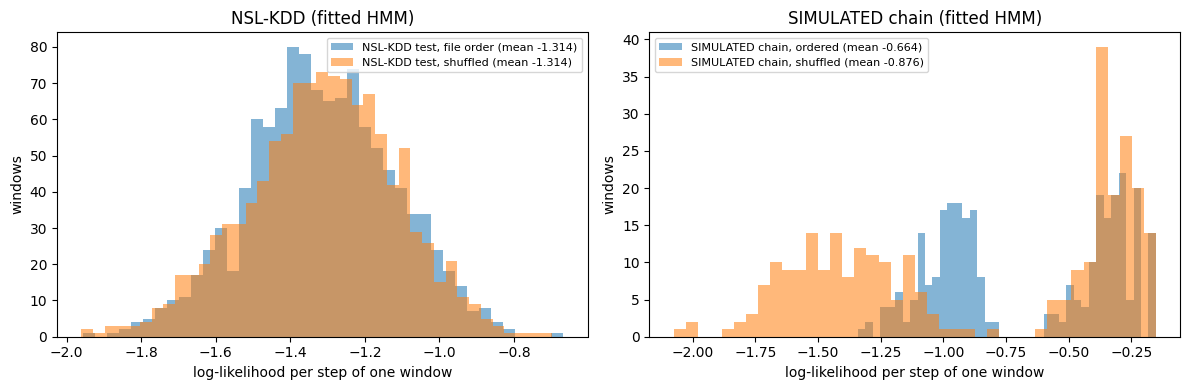

In [48]:
def per_step_loglik(hmm, windows):
    return hmm.score(windows) / windows.shape[1]


loglik_rows = {
    "NSL-KDD test, file order": per_step_loglik(nsl_hmm, to_windows(cluster_te, 20)),
    "NSL-KDD test, shuffled": per_step_loglik(nsl_hmm, to_windows(cluster_te[shuffle_order], 20)),
    "SIMULATED chain, ordered": per_step_loglik(sim_hmm, sim_test_x),
    "SIMULATED chain, shuffled": per_step_loglik(sim_hmm, sim_shuffled_x),
}
loglik_table = pd.Series({name: values.mean() for name, values in loglik_rows.items()}).to_frame("mean log-likelihood per step")
display(loglik_table.round(4))
nsl_loglik_gain = float(loglik_table.iloc[0, 0] - loglik_table.iloc[1, 0])
sim_loglik_gain = float(loglik_table.iloc[2, 0] - loglik_table.iloc[3, 0])
print(f"Gain from keeping the order: NSL-KDD {nsl_loglik_gain:+.4f} nats/step | SIMULATED {sim_loglik_gain:+.4f} nats/step")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, pair, title in [(axes[0], list(loglik_rows)[:2], "NSL-KDD (fitted HMM)"),
                        (axes[1], list(loglik_rows)[2:], "SIMULATED chain (fitted HMM)")]:
    for name in pair:
        ax.hist(loglik_rows[name], bins=40, alpha=0.55, label=f"{name} (mean {loglik_rows[name].mean():.3f})")
    ax.set_xlabel("log-likelihood per step of one window")
    ax.set_ylabel("windows")
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("../results/ids_nsl_kdd_hmm_loglik_ordered_vs_shuffled.png", dpi=120)
plt.show()

hmm_evidence = {
    "attack_lag1_autocorrelation_train_file_order": round(float(acf_rows["KDDTrain+ file order"][0]), 5),
    "attack_lag1_autocorrelation_train_shuffled": round(float(acf_rows["KDDTrain+ shuffled"][0]), 5),
    "attack_lag1_autocorrelation_test_file_order": round(float(acf_rows["KDDTest+ file order"][0]), 5),
    "attack_lag1_autocorrelation_test_shuffled": round(float(acf_rows["KDDTest+ shuffled"][0]), 5),
    "autocorrelation_noise_band_95": round(float(noise_band), 5),
    "mutual_information_bits": mi_table.round(5).reset_index().to_dict(orient="records"),
    "transition_file_vs_shuffled_max_abs_diff": round(transition_max_abs_diff, 5),
    "transition_file_vs_shuffled_frobenius": round(transition_frobenius_diff, 5),
    "transition_row_L1_to_stationary": dict(zip(CLASSES, np.round(row_vs_stationary_l1, 4).tolist())),
    "loglik_per_step": loglik_table.round(4)["mean log-likelihood per step"].to_dict(),
    "loglik_gain_from_order_nsl": round(nsl_loglik_gain, 5),
    "loglik_gain_from_order_simulated": round(sim_loglik_gain, 5),
    "cases_accuracy_macro_f1": hmm_cases_table.round(4).to_dict(orient="records"),
}

The fitted HMM gives the NSL-KDD test windows the same likelihood whether the rows are in file order or shuffled: keeping the order buys essentially nothing. On the simulated chain the ordered windows are much more likely than the shuffled ones, because there the order is real. This is the same story told with likelihood instead of accuracy.

**Result: the HMM fails on NSL-KDD, and it is the data's fault, not the model's.**
- File order, shuffled order and emission-only give the **same** accuracy, so the order of rows adds nothing.
- The same HMM code clearly beats shuffled and emission-only decoding on the simulated chain, so the model works; the real data has no order to use.
- The rows of the transition matrix are almost identical: the next row's family does not depend on the current one.
- The graphs above show the cause directly: consecutive labels carry almost no information about each other (near-zero mutual information and autocorrelation, same as shuffled), so the learned transitions are just the class mix and the likelihood does not improve with order (`06_hmm_*.png`).
- NSL-KDD records are independent connections with **no timestamps, no source/destination hosts and no sessions**, so there is no real sequence for an HMM to learn.

A multi-stage model needs data with host IDs and time. **That is why the next notebook (`ids_unsw.ipynb`) uses UNSW-NB15**, whose raw flows have source/destination IPs and start times.

## Task 22 — Save Results
*Source: Repo (saves outputs to `../results/`).*

In [49]:
summary = {
    "selected_classifier": SELECTED_NAME,
    "service_target_encoding_used": bool(USE_TARGET_ENCODING),
    "primary_mode": PRIMARY_MODE,
    "second_stage": S2_VERSION,
    "second_stage_threshold": S2_THRESHOLD,
    "u2r_share_cutoff": U2R_SHARE_CUTOFF,
    "anomaly_score": AF_SCORE,
    "naming_cutoff": NAMING_CUTOFF,
    "chosen_k": chosen_k,
    "final_table": final_table.round(4).reset_index().to_dict(orient="records"),
    "hmm": hmm_table.round(4).to_dict(orient="records"),
    "hmm_simulated_control": simulation_results.round(4).to_dict(orient="records"),
    "hmm_evidence": hmm_evidence,
    "runtime_seconds": round(time.time() - RUN_STARTED, 1),
}
with open("../results/ids_nsl_kdd_summary.json", "w") as handle:
    json.dump(summary, handle, indent=2, default=str)
validation_table.round(4).to_csv("../results/ids_nsl_kdd_validation_models.csv", index=False)
comparison.round(4).to_csv("../results/ids_nsl_kdd_test_all_candidates.csv", index=False)
print("Saved results to ../results/ | total runtime", summary["runtime_seconds"], "s")

Saved results to ../results/ | total runtime 432.6 s
